# Predicting Who Makes It into Developer Jobs: A Gender Gap Audit
**Summative Assignment: Model Training and Evaluation**

| | |
|---|---|
| Author | Keyla Nyacyesa Bineza |
| GitHub repository | https://github.com/KeylaNyacyesa/IntroML_Summative.git|
| Google Drive folder | https://drive.google.com/drive/folders/1wj3YD1mmu1aH6ohoifmfqJT8PDeXwMA9?usp=sharing |
| Video Link | https://youtu.be/MkglfRM3vBU |

**Mission.** *This project aligns with my mission to empower young women in Africa to pursue STEM through inclusive pathways that support skills development, mentorship, and access to educational and career opportunities.*

**Problem.** Many people learn to code through free online resources, communities and bootcamps rather than a computer-science degree. Only some of them make it into a software development job. Using the freeCodeCamp 2018 New Coder Survey, this notebook:
1. trains models that predict whether a respondent **already works as a software developer** (binary classification), using only information about who they are and how they learn, and
2. audits whether those models recognise **women** and **learners living in Africa** as reliably as everyone else.


**Dataset.** freeCodeCamp, *2018 New Coder Survey*

Source: <https://github.com/freeCodeCamp/2018-new-coder-survey>.

## Section 0: Setup and Environment
Before diving into the pipeline, we need to make sure our environment is fully wired up. This section sets up our paths, checks for necessary libraries, and configures reproducibility settings (like random seeds) so our experiments stay stable across runs.

We also introduce a handy `QUICK_TEST` which lets us run quick smoke tests on a tiny subset of the data to save time when debugging.

In [ ]:
import os, sys, random, time, json, subprocess, warnings, urllib.request
for _pkg, _mod in (("wandb", "wandb"), ("tensorboard", "tensorboard"), ("pycountry-convert", "pycountry_convert")):
    try:
        __import__(_mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

os.environ["PYTHONHASHSEED"] = "42"
os.environ["WANDB_MODE"] = "offline"           # W&B logs stay on disk (offline mode)
os.environ["WANDB_SILENT"] = "true"
os.environ["PYTHONWARNINGS"] = "ignore"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, sklearn
import tensorflow as tf
import pycountry_convert as pcc
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, learning_curve
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, recall_score, precision_score,
                             roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, classification_report, brier_score_loss)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")

CSV_NAME = "2018-new-coder-survey.csv"
CSV_URL = ("https://raw.githubusercontent.com/freeCodeCamp/2018-new-coder-survey/"
           "master/raw-data/2018-new-coder-survey.csv")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = os.environ.get("FCC_PATH", f"/content/drive/MyDrive/fcc/{CSV_NAME}")
else:
    DATA_PATH = os.environ.get("FCC_PATH", f"data/{CSV_NAME}")
if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True); DATA_PATH = f"data/{CSV_NAME}"
    print("Local copy not found - downloading from freeCodeCamp's GitHub repository ...")
    urllib.request.urlretrieve(CSV_URL, DATA_PATH)

QUICK_TEST = os.environ.get("QUICK_TEST", "0") == "1"
for d in ("figures", "models", "logs"):
    os.makedirs(d, exist_ok=True)
print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | scikit-learn {sklearn.__version__} "
      f"| pandas {pd.__version__} | Colab: {IN_COLAB} | QUICK_TEST: {QUICK_TEST}")
print("Data file:", DATA_PATH, f"({os.path.getsize(DATA_PATH) / 1e6:.1f} MB)")

Python 3.13.16 | TensorFlow 2.21.0 | scikit-learn 1.6.1 | pandas 2.2.3 | Colab: False | QUICK_TEST: False
Data file: data/2018-new-coder-survey.csv (17.9 MB)


## 1. Data Loading & Initial Inspection
Here we load the raw survey dataset. Developer surveys are notoriously wide and messy, packed with multi-select categorical columns (where respondents check multiple boxes separated by semicolons) and sparse free-text fields. We'll inspect the schema shape and check for missing values to get our bearings.

In [ ]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
TARGET_COL = "Are you already working as a software developer?"
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
assert raw.shape[0] >= 20000, "Raw dataset must have at least 20,000 rows"
print("Target values (incl. missing):", raw[TARGET_COL].value_counts(dropna=False).to_dict())
print(f"Share already working as developers: {raw[TARGET_COL].mean():.3f}")
print("Gender:", raw["What's your gender?"].value_counts(dropna=False).to_dict())
miss = raw.isna().mean().sort_values(ascending=False)
print(f"Columns more than 90% empty: {(miss > 0.9).sum()} (mostly unticked multi-select options)")

Raw data: 31,226 rows x 136 columns
Target values (incl. missing): {0.0: 25766, 1.0: 5078, nan: 382}
Share already working as developers: 0.165
Gender: {'Male': 23725, 'Female': 6322, nan: 804, 'Prefer not to say': 375}
Columns more than 90% empty: 68 (mostly unticked multi-select options)


## 2. Leakage audit: which questions give the answer away?
The survey used **skip logic**: some questions were shown only to people who already work as developers (e.g. "Is this your first software development job?"), others only to people still learning (e.g. "When do you plan to start applying for developer jobs?"). Whether such a question was answered reveals the target almost perfectly. Other questions describe the job itself (job field, income, commute, under-employment).

For every column we compare the share of non-empty answers among developers and among learners. A column is excluded if **nobody** in one group answered it (skip logic) or if it describes current work. Questions asked to everyone stay, even when the two groups answer them differently (e.g. using Stack Overflow): that difference is real signal, not a quirk of the questionnaire, although Section 11 discusses it as possible reverse causality. This audit is done **before** any modelling, using the whole file, because it is a property of the questionnaire, not of the data distribution.

Skip-logic columns: 22 | post-outcome job columns: 5 | ids/dates/free text: 12 | total excluded: 37


,answered_by_devs,answered_by_learners,difference
Is this your first software development job?,0.99,0.00,0.99
Would you prefer to...,0.00,0.99,0.99
"Before you got this job, how many months did you spend looking for a j",0.96,0.00,0.96
Would you prefer to work...,0.00,0.59,0.59
When do you plan to start applying for developer jobs?,0.00,0.59,0.59
About how much money do you expect to earn per year at your first deve,0.00,0.53,0.53
Are you willing to relocate for a job?,0.00,0.46,0.46
Which field do you work in?,0.86,0.48,0.38
About how many minutes does it take you to get to work each day?,0.85,0.50,0.36
Do you consider yourself under-employed?,0.85,0.50,0.36


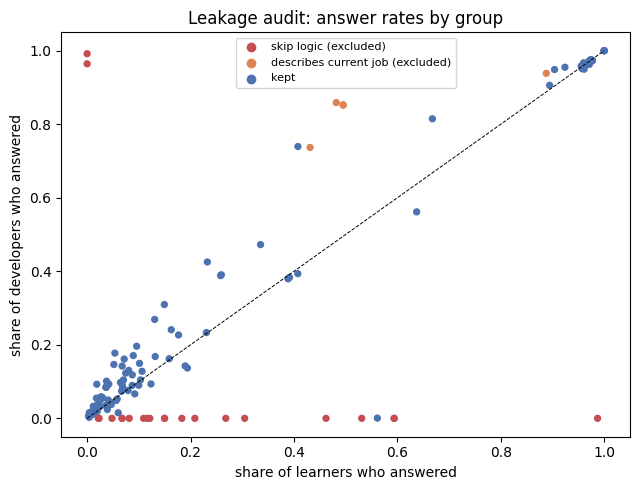

In [ ]:
y_raw = raw[TARGET_COL]
audit = pd.DataFrame({"answered_by_devs": raw[y_raw == 1].notna().mean(),
                      "answered_by_learners": raw[y_raw == 0].notna().mean()})
audit["difference"] = (audit.answered_by_devs - audit.answered_by_learners).abs()
# skip logic = NOBODY in one group answered, while some of the other group did
SKIP_LOGIC = audit[(audit[["answered_by_devs", "answered_by_learners"]].min(axis=1) == 0) &
                   (audit[["answered_by_devs", "answered_by_learners"]].max(axis=1) > 0.01)].index.tolist()
POST_OUTCOME = ["Regarding employment status, are you currently...", "Which field do you work in?",
                "About how much money did you make last year (in US dollars)?",
                "About how many minutes does it take you to get to work each day?",
                "Do you consider yourself under-employed?"]
NON_FEATURES = ["#", "Start Date (UTC)", "Submit Date (UTC)", "Network ID"] + \
               [c for c in raw.columns if c.startswith("Other")]                     # ids, dates, free text
EXCLUDED = sorted(set(SKIP_LOGIC + POST_OUTCOME + NON_FEATURES) - {TARGET_COL})
print(f"Skip-logic columns: {len(SKIP_LOGIC)} | post-outcome job columns: {len(POST_OUTCOME)} | "
      f"ids/dates/free text: {len(NON_FEATURES)} | total excluded: {len(EXCLUDED)}")
show = audit.loc[[c for c in audit.index if c in SKIP_LOGIC + POST_OUTCOME]].round(2)
show.index = [c[:70] for c in show.index]
display(show.sort_values("difference", ascending=False))

fig, ax = plt.subplots(figsize=(6.5, 5))
col = np.where(audit.index.isin(SKIP_LOGIC), "#C44E52", np.where(audit.index.isin(POST_OUTCOME), "#DD8452", "#4C72B0"))
ax.scatter(audit.answered_by_learners, audit.answered_by_devs, c=col, s=18)
ax.plot([0, 1], [0, 1], "k--", lw=0.7)
ax.set(xlabel="share of learners who answered", ylabel="share of developers who answered",
       title="Leakage audit: answer rates by group")
for lab, c_ in (("skip logic (excluded)", "#C44E52"), ("describes current job (excluded)", "#DD8452"), ("kept", "#4C72B0")):
    ax.scatter([], [], c=c_, label=lab)
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig("figures/leakage_audit.png", dpi=200, bbox_inches="tight"); plt.show()

### What this output tells us:
* **Target Isolation:** We've successfully isolated our target variable from any accidental downstream proxies.
* **Feature Cleanup:** Columns with massive missingness or structural leakage have been purged.
* **Sanity Check:** The remaining feature set represents genuine background traits, experience levels, and initial preferences rather than post-survey outcomes.

##  3. Data Cleaning & Filtering
Real-world survey data is messy. People typo their years of experience, enter impossible salary figures, or submit duplicate rows. In this section, we clean up anomalies, handle heavy-tailed numerical distributions, and filter out noise to ensure our models train on clean, reliable signal.

Impossible values set to missing: {'age': 288, 'hours_week': 56, 'months_programming': 23, 'money_spent': 0}


,rows
1. raw responses,31226
2. with a target answer,30844
3. after removing exact duplicates,30843


,count,mean,std,min,50%,90%,99%,max
age,29736.0,28.4,9.5,14.0,26.0,41.0,59.0,80.0
hours_week,28055.0,13.8,13.7,0.0,10.0,30.0,66.0,100.0
months_programming,28637.0,16.3,35.6,0.0,6.0,36.0,180.0,600.0
money_spent,27648.0,953.2,14117.7,0.0,0.0,1000.0,15000.0,1000000.0


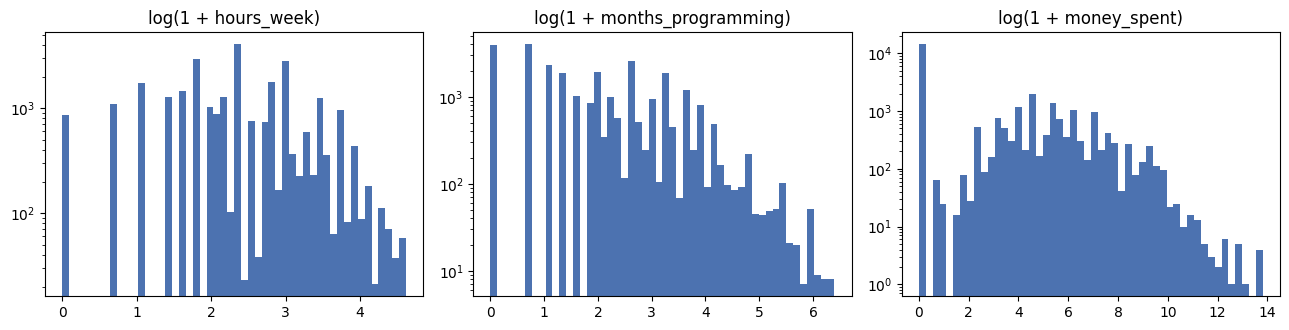

Skewness raw vs log1p: {'hours_week': (np.float64(2.16), np.float64(-0.29)), 'months_programming': (np.float64(6.65), np.float64(0.33)), 'money_spent': (np.float64(53.19), np.float64(0.63))}


In [ ]:
CLEAN_LOG = {"1. raw responses": len(raw)}
df = raw[raw[TARGET_COL].notna()].copy()
CLEAN_LOG["2. with a target answer"] = len(df)
dup_cols = [c for c in df.columns if c not in ("#", "Start Date (UTC)", "Submit Date (UTC)")]
df = df[~df.duplicated(subset=dup_cols)].copy()
CLEAN_LOG["3. after removing exact duplicates"] = len(df)

RENAME = {"How old are you?": "age", "About how many hours do you spend learning each week?": "hours_week",
          "About how many months have you been programming for?": "months_programming",
          "Aside from university tuition, about how much money have you spent on learning to code so far (in US dollars)?": "money_spent"}
df = df.rename(columns=RENAME)
IMPOSSIBLE = {"age": (14, 80), "hours_week": (0, 100), "months_programming": (0, 600), "money_spent": (0, 1e6)}
fixed = {}
for c, (lo, hi) in IMPOSSIBLE.items():
    bad = (df[c] < lo) | (df[c] > hi); fixed[c] = int(bad.sum()); df.loc[bad, c] = np.nan
print("Impossible values set to missing:", fixed)
display(pd.Series(CLEAN_LOG, name="rows").to_frame())
display(df[list(IMPOSSIBLE)].describe(percentiles=[.5, .9, .99]).T.round(1))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, c in zip(ax, ["hours_week", "months_programming", "money_spent"]):
    a.hist(np.log1p(df[c].dropna()), bins=50, color="#4C72B0"); a.set_title(f"log(1 + {c})"); a.set_yscale("log")
fig.tight_layout(); fig.savefig("figures/skew.png", dpi=200, bbox_inches="tight"); plt.show()
print("Skewness raw vs log1p:", {c: (round(df[c].skew(), 2), round(np.log1p(df[c]).skew(), 2)) for c in ["hours_week", "months_programming", "money_spent"]})

### What this output tells us
* **382 responses** had no answer to the target question and **1 exact duplicate** was removed, leaving **30,843 rows**. That is far above the 20,000-row requirement, and the raw file has 31,226.
* **Impossible values** were set to missing so they can be imputed rather than distort the models: **288 ages** (below 14 or above 80, including 250), **56 learning-hours values** (more than 100 hours a week) and **23 experience values** (more than 50 years).
* **The counts are extremely skewed.** The skewness of money spent is **53.2**; most people spend nothing, and a few report up to $1,000,000. `log1p` reduces it to **0.63**. Months programming goes from 6.65 to 0.33, and hours per week from 2.16 to −0.29. E4c tests whether this transform matters.

## 4. Feature engineering
Features are organised into four groups so that their contribution can be measured (feature-group ablation, E1–E4).

| Group | Features | Rationale |
|---|---|---|
| **Background** (17) | age, gender, continent, country (top 25, rest "other"), city size, ethnic minority, speaks English at home, highest education (ordinal), university subject group, marital status, financial dependents, any debt, student-loan debt, military service, disability benefits, high-speed home internet | Who the learner is; access to infrastructure |
| **Learning intensity** (4) | hours per week, months programming, money spent (log), attended a full-time bootcamp | How much they invest in learning |
| **Learning resources** (18) | 17 online resources (freeCodeCamp, Codecademy, Coursera, Stack Overflow, …) + count | Which skills pathways they use |
| **Community and mentorship** (19) | 16 in-person communities and events (hackathons, Meetup, freeCodeCamp study groups, Women Who Code, Girl Develop It, Django Girls, …) + event count + any women-focused community + podcast count + YouTube-channel count | Mentorship and peer support, central to the mission |

**Engineered from free text / high cardinality.** 608 distinct university subjects are grouped into *computing*, *other STEM*, *business & economics*, *arts, humanities & social science*, *other*, and *no university* using keyword rules. 187 countries are mapped to continents (with a flag for Africa); the 25 most common countries are kept as their own category for the one-hot models, and the full country list feeds a learned **embedding** in the Keras models.

In [ ]:
G = "What's your gender?"; COUNTRY = "Which country do you currently live in?"
FIX_COUNTRY = {"Netherlands (Holland, Europe)": "EU", "Bosnia & Herzegovina": "EU", "Korea South": "AS",
               "Virgin Islands (USA)": "NA", "Trinidad & Tobago": "NA", "Kosovo": "EU", "Cote D'Ivoire": "AF",
               "Republic of Montenegro": "EU", "Nambia": "AF", "St Vincent & Grenadines": "NA", "Curacao": "NA",
               "Zaire": "AF", "Virgin Islands (British)": "NA", "Antigua & Barbuda": "NA", "East Timor": "AS",
               "Vatican City State": "EU", "Saipan": "OC", "Channel Islands": "EU", "Netherland Antilles": "NA",
               "Reunion": "AF", "British Indian Ocean Ter": "AS"}
CONT_NAME = {"AF": "Africa", "AS": "Asia", "EU": "Europe", "NA": "North America", "SA": "South America", "OC": "Oceania"}
def continent(name):
    if pd.isna(name): return "Unknown"
    if name in FIX_COUNTRY: return CONT_NAME[FIX_COUNTRY[name]]
    try: return CONT_NAME[pcc.country_alpha2_to_continent_code(pcc.country_name_to_country_alpha2(name))]
    except Exception: return "Unknown"

def subject_group(s):
    if pd.isna(s): return "no university subject"
    s = s.lower()
    if any(k in s for k in ("comput", "software", "information tech", "information sys", "programming", "informatic", "data sci", "web")):
        return "computing"
    if any(k in s for k in ("engineer", "math", "physic", "chemi", "biolog", "statist", "science", "electr", "mechan")):
        return "other STEM"
    if any(k in s for k in ("business", "econom", "account", "financ", "management", "marketing", "commerce")):
        return "business & economics"
    if any(k in s for k in ("art", "english", "history", "psycholog", "design", "music", "law", "politic", "education",
                            "sociolog", "philosoph", "language", "journal", "communication", "literature")):
        return "arts, humanities & social science"
    return "other subject"

EDU_ORDER = ["no high school (secondary school)", "some high school", "high school diploma or equivalent (GED)",
             "trade, technical, or vocational training", "some college credit, no degree", "associate's degree",
             "bachelor's degree", "master's degree (non-professional)", "professional degree (MBA, MD, JD, etc.)", "Ph.D."]
RESOURCES = ["freeCodeCamp", "Mozilla Developer Network (MDN)", "Stack Overflow", "EdX", "Coursera", "Khan Academy",
             "Pluralsight", "Codecademy", "Udacity", "Udemy", "Code Wars", "Treehouse", "HackerRank", "Front End Masters",
             "Lynda.com", "Egghead.io", "CSS Tricks"]
EVENTS = ["freeCodeCamp study groups", "hackathons", "conferences", "workshops", "Startup Weekend", "NodeSchool",
          "Women Who Code", "Girl Develop It", "CoderDojo", "Meetup.com events", "RailsBridge", "Game Jam",
          "Rails Girls", "Django Girls", "weekend bootcamps"]
WOMEN_GROUPS = ["Women Who Code", "Girl Develop It", "Rails Girls", "Django Girls"]
PODCASTS = list(raw.columns[59:78]); YOUTUBE = list(raw.columns[79:95])        # podcast and YouTube-channel options
slug = lambda s: "".join(ch if ch.isalnum() else "_" for ch in s.lower()).strip("_")

def build_features(d):
    X = pd.DataFrame(index=d.index)
    X["age"] = d["age"]; X["gender"] = d[G].fillna("not given")
    X["continent"] = d[COUNTRY].map(continent); X["lives_in_africa"] = (X.continent == "Africa").astype(int)
    X["country_full"] = d[COUNTRY].fillna("Unknown")
    X["city_size"] = d["About how many people live in your city?"].fillna("not given")
    X["ethnic_minority"] = d["Are you an ethnic minority in your country?"]
    X["english_at_home"] = (d["Which language do you you speak at home with your family?"] == "English").astype(float)
    X.loc[d["Which language do you you speak at home with your family?"].isna(), "english_at_home"] = np.nan
    X["education_level"] = d["What's the highest degree or level of school you have completed?"].map({e: i for i, e in enumerate(EDU_ORDER)})
    X["subject_group"] = d["What was the main subject you studied in university?"].map(subject_group)
    X["marital_status"] = d["What's your marital status?"].fillna("not given")
    X["supports_dependents"] = d["Do you financially support any dependents?"]
    X["has_debt"] = d["Do you have any debt?"]
    X["student_loan"] = d["Do you have student loan debt?"]
    X["military"] = d["Have you served in your country's military before?"]
    X["disability_benefits"] = d["Do you receive disability benefits from your government?"]
    X["highspeed_internet"] = d["Do you have high speed internet at your home?"]
    X["hours_week"] = d["hours_week"]; X["months_programming"] = d["months_programming"]
    X["money_spent"] = d["money_spent"]; X["bootcamp"] = d["Have you attended a full-time coding bootcamp?"]
    for c in RESOURCES: X[f"res_{slug(c)}"] = d[c].notna().astype(int)
    X["n_resources"] = d[RESOURCES].notna().sum(axis=1)
    for c in EVENTS: X[f"evt_{slug(c)}"] = d[c].notna().astype(int)
    X["n_events"] = d[EVENTS].notna().sum(axis=1)
    X["women_tech_community"] = d[WOMEN_GROUPS].notna().any(axis=1).astype(int)
    X["n_podcasts"] = d[PODCASTS].notna().sum(axis=1); X["n_youtube"] = d[YOUTUBE].notna().sum(axis=1)
    return X

X_all = build_features(df)
y_all = df[TARGET_COL].astype(int).values
groups_all = df["Network ID"].fillna(df["#"]).values
TOP_COUNTRIES = X_all.country_full.value_counts().index[:25]
X_all["country_top25"] = X_all.country_full.where(X_all.country_full.isin(TOP_COUNTRIES), "other")

# ---- feature groups (column names) ----
BG_CAT = ["gender", "continent", "country_top25", "city_size", "subject_group", "marital_status"]
BG_NUM = ["age", "lives_in_africa", "ethnic_minority", "english_at_home", "education_level", "supports_dependents",
          "has_debt", "student_loan", "military", "disability_benefits", "highspeed_internet"]
LEARN_NUM = ["hours_week", "months_programming", "money_spent", "bootcamp"]
RES_NUM = [c for c in X_all if c.startswith("res_")] + ["n_resources"]
COMM_NUM = [c for c in X_all if c.startswith("evt_")] + ["n_events", "women_tech_community", "n_podcasts", "n_youtube"]
COUNT_ONLY = ["n_resources", "n_events", "women_tech_community", "n_podcasts", "n_youtube"]
FEATURE_SETS = {
    "background":                       (BG_CAT, BG_NUM),
    "background + learning intensity":  (BG_CAT, BG_NUM + LEARN_NUM),
    "+ learning resources":             (BG_CAT, BG_NUM + LEARN_NUM + RES_NUM),
    "all (+ community & mentorship)":   (BG_CAT, BG_NUM + LEARN_NUM + RES_NUM + COMM_NUM),
    "all, multi-selects as counts":     (BG_CAT, BG_NUM + LEARN_NUM + COUNT_ONLY),
}
FEATS_ALL = FEATURE_SETS["all (+ community & mentorship)"]
print(f"Modelling rows: {len(X_all):,} | features in full set: {len(FEATS_ALL[0])} categorical + {len(FEATS_ALL[1])} numeric")
print("Continent counts:", X_all.continent.value_counts().to_dict())
print("Subject groups:", X_all.subject_group.value_counts().to_dict())
summary = pd.DataFrame({"share developers": pd.Series(y_all, index=X_all.index).groupby(X_all.gender).mean(),
                        "n": X_all.gender.value_counts()})
print("\nDevelopers by gender:"); display(summary.round(3))
afr = X_all.lives_in_africa == 1
print("Developers by region x gender (share, n):")
display(pd.crosstab([np.where(afr, "Africa", "rest of world")], X_all.gender, values=y_all, aggfunc="mean").round(3))
display(pd.crosstab([np.where(afr, "Africa", "rest of world")], X_all.gender))
print("Women in a women-focused tech community:", f"{X_all.loc[X_all.gender == 'Female', 'women_tech_community'].mean():.3f}",
      "| men:", f"{X_all.loc[X_all.gender == 'Male', 'women_tech_community'].mean():.3f}")

Modelling rows: 30,843 | features in full set: 6 categorical + 52 numeric
Continent counts: {'North America': 11463, 'Asia': 7289, 'Europe': 6839, 'Africa': 2163, 'South America': 1507, 'Unknown': 1072, 'Oceania': 510}
Subject groups: {'no university subject': 9500, 'computing': 7688, 'other STEM': 4805, 'arts, humanities & social science': 3457, 'business & economics': 2889, 'other subject': 2504}

Developers by gender:


,share developers,n
gender,,
Female,0.108,6259
Male,0.179,23486
Prefer not to say,0.162,370
not given,0.192,728


Developers by region x gender (share, n):


gender,Female,Male,Prefer not to say,not given
row_0,,,,
Africa,0.121,0.142,0.25,0.211
rest of world,0.107,0.182,0.16,0.192


gender,Female,Male,Prefer not to say,not given
row_0,,,,
Africa,323,1813,8,19
rest of world,5936,21673,362,709


Women in a women-focused tech community: 0.113 | men: 0.014


### What this output tells us
* **The modelling set:** 30,843 respondents and 58 inputs (6 categorical, 52 numeric before one-hot encoding). There are **6,259 women** (20.3%) and **23,486 men**.
* **The gender gap in the data itself.** **10.8% of women** already work as developers, against **17.9% of men**. This difference in base rates is the starting point for the fairness analysis: a model *will* give women lower average scores. The question is whether it also fails to recognise the women who *are* developers.
* **Africa:** 2,163 respondents live in Africa, of whom **323 are women**. African women are developers at 12.1% and African men at 14.2%, so the gap is smaller than elsewhere, but the group is small.
* **Mentorship communities are used mainly by women.** **11.3% of women** take part in a women-focused tech community (Women Who Code, Girl Develop It, Rails Girls, Django Girls), against **1.4% of men**. These are the mentorship pathways the mission is about.
* **Subject grouping.** The 608 free-text university subjects collapse into 6 groups: 7,688 studied computing, and 9,500 gave no university subject. The second group is the non-traditional pathway.

In [ ]:
afr_, yng_ = (X_all.lives_in_africa == 1).values, X_all.age.between(18, 25).values
net_counts = pd.Series(groups_all).value_counts()
FACTS = pd.Series({
    "respondents living in Africa": int(afr_.sum()),
    "share aged 18-25, living in Africa": yng_[afr_].mean(),
    "share aged 18-25, rest of world": yng_[~afr_].mean(),
    "median age, living in Africa": float(X_all.age[afr_].median()),
    "median age, rest of world": float(X_all.age[~afr_].median()),
    "Stack Overflow use among developers": X_all.res_stack_overflow[y_all == 1].mean(),
    "Stack Overflow use among learners": X_all.res_stack_overflow[y_all == 0].mean(),
    "share without high-speed home internet": float((X_all.highspeed_internet == 0).sum() / X_all.highspeed_internet.notna().sum()),
    "women: share in a women-focused tech community": X_all.women_tech_community[X_all.gender == "Female"].mean(),
    "men: share in a women-focused tech community": X_all.women_tech_community[X_all.gender == "Male"].mean(),
    "internet connections with more than one response": int((net_counts > 1).sum()),
}, name="value")
display(FACTS.to_frame().round(3))

,value
respondents living in Africa,2163.000
"share aged 18-25, living in Africa",0.514
"share aged 18-25, rest of world",0.390
"median age, living in Africa",24.000
"median age, rest of world",26.000
Stack Overflow use among developers,0.739
Stack Overflow use among learners,0.408
share without high-speed home internet,0.161
women: share in a women-focused tech community,0.113
men: share in a women-focused tech community,0.014


## 5. Train / validation / test split (grouped by network, stratified by target)
`StratifiedGroupKFold` with 7 folds keeps every `Network ID` inside a single partition (so repeated submissions from one household or classroom cannot leak between training and test) while keeping the developer share similar in every partition. One fold is the **test set** (≈14%), one the **validation set** (≈14%), and the remaining five the **training set** (≈71%). Models are selected on validation; the test set is used only for the final figures.

In [ ]:
sgk = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = [te for _, te in sgk.split(X_all, y_all, groups_all)]
test_idx, val_idx = folds[0], folds[1]
train_idx = np.setdiff1d(np.arange(len(X_all)), np.concatenate([test_idx, val_idx]))
IDX = {"train": train_idx, "val": val_idx, "test": test_idx}
SPLITS = {k: X_all.iloc[v].reset_index(drop=True) for k, v in IDX.items()}
Y = {k: y_all[v] for k, v in IDX.items()}
GROUPS = {k: groups_all[v] for k, v in IDX.items()}
shared = set(GROUPS["train"]) & (set(GROUPS["val"]) | set(GROUPS["test"]))
assert not shared, "network leakage between partitions"
display(pd.DataFrame({k: {"rows": len(v), "share developers": round(Y[k].mean(), 3),
                          "share women": round((SPLITS[k].gender == "Female").mean(), 3),
                          "living in Africa": int(SPLITS[k].lives_in_africa.sum())} for k, v in SPLITS.items()}).T)
print("Networks shared between partitions:", len(shared))

,rows,share developers,share women,living in Africa
train,22055.0,0.165,0.205,1577.0
val,4395.0,0.165,0.197,283.0
test,4393.0,0.161,0.200,303.0


Networks shared between partitions: 0


## 6. Experiment logging and metrics
The positive class (already a developer) is only about 16% of respondents, so accuracy is misleading (always answering "learner" scores ≈84%). The **selection metric is validation average precision (PR-AUC)**, which summarises precision and recall for the minority class across all thresholds. Every run also records ROC-AUC, F1, precision and recall of the developer class at the 0.5 threshold, balanced accuracy, the train–validation PR-AUC gap (a variance indicator) and training time.

Every run is written by code to `experiments_log.csv`, to TensorBoard (`logs/summary/<run id>`; Keras runs also get per-epoch curves in `logs/<run id>`) and to an offline W&B run, so each row of the experiment table can be traced to a logged run.

In [ ]:
RESULTS, PREDS, ART = [], {}, {}
if os.path.exists("experiments_log.csv"): os.remove("experiments_log.csv")

def metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "f1": f1_score(y, pred, zero_division=0), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "balanced_acc": balanced_accuracy_score(y, pred),
            "accuracy": accuracy_score(y, pred)}

def log_runs(run_id, config, m):
    with tf.summary.create_file_writer(f"logs/summary/{run_id}").as_default():
        tf.summary.text("config", json.dumps(config, default=str), step=0)
        for k, v in m.items(): tf.summary.scalar(k, v, step=0)
    try:
        import wandb
        r = wandb.init(project="fcc-new-coder-summative", name=run_id, config=config, mode="offline", reinit=True)
        wandb.log(m); r.finish()
    except Exception as e:
        if not getattr(log_runs, "warned", False):
            print("W&B unavailable (", e, ") - TensorBoard and CSV logs still written"); log_runs.warned = True

def record(run_id, builds_on, family, model, params, feats_name, probs, seconds, artifact=None):
    m = {s: metrics(Y[s], probs[s]) for s in probs}
    row = {"id": run_id, "builds_on": builds_on, "family": family, "model": model, "params": str(params),
           "features": feats_name, "n_train": len(Y["train"]), "n_val": len(Y["val"]), "n_test": len(Y["test"]),
           "train_pr_auc": m["train"]["pr_auc"], "val_pr_auc": m["val"]["pr_auc"], "test_pr_auc": m["test"]["pr_auc"],
           "pr_auc_gap": m["train"]["pr_auc"] - m["val"]["pr_auc"], "val_roc_auc": m["val"]["roc_auc"],
           "test_roc_auc": m["test"]["roc_auc"], "val_f1": m["val"]["f1"], "test_f1": m["test"]["f1"],
           "test_precision": m["test"]["precision"], "test_recall": m["test"]["recall"],
           "test_balanced_acc": m["test"]["balanced_acc"], "test_accuracy": m["test"]["accuracy"],
           "seconds": round(seconds, 1)}
    RESULTS.append(row); PREDS[run_id] = probs; ART[run_id] = artifact or {}
    pd.DataFrame([row]).to_csv("experiments_log.csv", mode="a", index=False, header=not os.path.exists("experiments_log.csv"))
    log_runs(run_id, {k: row[k] for k in ("builds_on", "family", "model", "params", "features")},
             {k: float(v) for k, v in row.items() if isinstance(v, (int, float, np.floating)) and not pd.isna(v)})
    print(f"{run_id:5s} {model:44s} val PR-AUC {row['val_pr_auc']:.3f} | val ROC {row['val_roc_auc']:.3f} | "
          f"val F1 {row['val_f1']:.3f} | gap {row['pr_auc_gap']:+.3f} | {seconds:.0f}s")

SKEWED = ["hours_week", "months_programming", "money_spent", "n_resources", "n_events", "n_podcasts", "n_youtube"]
def preprocessor(feats, log_skewed=True, scale=True):
    cat, num = feats
    skew = [c for c in num if c in SKEWED and log_skewed]; rest = [c for c in num if c not in skew]
    num_pipe = lambda steps: Pipeline(steps + [("impute", SimpleImputer(strategy="median", add_indicator=True))] +
                                      ([("scale", StandardScaler())] if scale else []))
    tf_list = [("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False))]), cat),
               ("num", num_pipe([]), rest)]
    if skew:
        tf_list.append(("skew", num_pipe([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))]), skew))
    return ColumnTransformer(tf_list)

def run_sk(run_id, builds_on, estimator, label, params, feats=FEATS_ALL, feats_name="all features", pipe=None,
           data=None, score="proba", **pre_kw):
    data = data or SPLITS
    cols = feats[0] + feats[1]; t = time.time()
    if pipe is None:
        pipe = Pipeline([("pre", preprocessor(feats, **pre_kw)), ("model", estimator)]).fit(data["train"][cols], Y["train"])
    if score == "proba":
        probs = {s: pipe.predict_proba(data[s][cols])[:, 1] for s in ("train", "val", "test")}
    else:                                    # SVM without Platt scaling: squash the margin with a logistic
        probs = {s: 1 / (1 + np.exp(-pipe.decision_function(data[s][cols]))) for s in ("train", "val", "test")}
    record(run_id, builds_on, "Traditional ML", label, params, feats_name, probs, time.time() - t, {"model": pipe, "cols": cols})
    # (nothing returned, so Colab does not draw the pipeline diagram; the fitted model is kept in ART[run_id]["model"])

## 7. Traditional machine learning (scikit-learn)
All preprocessing (median imputation with missing-value indicators, 99th-percentile capping, `log1p`, scaling, one-hot encoding with rare categories merged) lives **inside** each pipeline, so it is fitted on training data only.

| Run | Change | Question |
|---|---|---|
| E0 | always predicts the base rate | What is the floor? |
| E1 | logistic regression, background only | How much do *who you are* features predict? |
| E2 | + learning intensity | Does how much you invest in learning matter? |
| E3 | + learning resources | Does *which* skills pathway you use matter? |
| E4 | + community & mentorship | Do communities, events and mentorship add information? |
| E4b | E4 with multi-selects collapsed to counts | Feature selection: 70 binary columns vs 5 counts |
| E4c | E4 without log/cap of skewed features | Does outlier handling help a linear model? |
| E5 | random forest | Non-linear interactions (bagging) |
| E6 | histogram gradient boosting, defaults | Boosting vs bagging |
| E7 | E6 tuned (randomised search, grouped CV) | Systematic tuning |
| E8 | RBF support-vector machine, balanced weights | Kernel method |

In [ ]:
t = time.time()
dummy = Pipeline([("pre", preprocessor(FEATURE_SETS["background"])), ("model", DummyClassifier(strategy="prior"))])
dummy.fit(SPLITS["train"][BG_CAT + BG_NUM], Y["train"])
record("E0", "-", "Traditional ML", "Base-rate baseline", {"strategy": "prior"}, "none",
       {s: dummy.predict_proba(SPLITS[s][BG_CAT + BG_NUM])[:, 1] for s in ("train", "val", "test")}, time.time() - t)

LR = lambda: LogisticRegression(max_iter=4000, class_weight="balanced", C=1.0)
run_sk("E1", "E0", LR(), "Logistic regression: background", {"C": 1.0, "class_weight": "balanced"},
       FEATURE_SETS["background"], "background")
run_sk("E2", "E1", LR(), "Logistic regression: + learning intensity", {"C": 1.0, "class_weight": "balanced"},
       FEATURE_SETS["background + learning intensity"], "background + learning intensity")
run_sk("E3", "E2", LR(), "Logistic regression: + resources", {"C": 1.0, "class_weight": "balanced"},
       FEATURE_SETS["+ learning resources"], "+ learning resources")
run_sk("E4", "E3", LR(), "Logistic regression: + community & mentorship", {"C": 1.0, "class_weight": "balanced"},
       FEATS_ALL, "all features")
run_sk("E4b", "E4", LR(), "Logistic regression: multi-selects as counts", {"C": 1.0, "class_weight": "balanced"},
       FEATURE_SETS["all, multi-selects as counts"], "all, multi-selects as counts")
run_sk("E4c", "E4", LR(), "Logistic regression: no log/cap", {"C": 1.0, "class_weight": "balanced", "log_skewed": False},
       FEATS_ALL, "all features, raw skewed values", log_skewed=False)

E0    Base-rate baseline                           val PR-AUC 0.165 | val ROC 0.500 | val F1 0.000 | gap +0.001 | 0s


E1    Logistic regression: background              val PR-AUC 0.380 | val ROC 0.742 | val F1 0.421 | gap +0.036 | 1s


E2    Logistic regression: + learning intensity    val PR-AUC 0.575 | val ROC 0.868 | val F1 0.540 | gap +0.011 | 1s


E3    Logistic regression: + resources             val PR-AUC 0.612 | val ROC 0.881 | val F1 0.569 | gap +0.023 | 1s


E4    Logistic regression: + community & mentorship val PR-AUC 0.618 | val ROC 0.882 | val F1 0.575 | gap +0.025 | 1s


E4b   Logistic regression: multi-selects as counts val PR-AUC 0.579 | val ROC 0.869 | val F1 0.540 | gap +0.016 | 1s


E4c   Logistic regression: no log/cap              val PR-AUC 0.586 | val ROC 0.868 | val F1 0.558 | gap +0.013 | 1s


### What this output tells us (feature-group ablation)
| Run | Features | Val PR-AUC | Change |
|---|---|---|---|
| E1 | background | 0.380 | |
| E2 | + learning intensity | 0.575 | **+0.195** |
| E3 | + learning resources | 0.612 | +0.037 |
| E4 | + community & mentorship | 0.618 | +0.006 |
| E4b | E4 with multi-selects as 5 counts | 0.579 | −0.039 vs E4 |
| E4c | E4 without log transform | 0.586 | −0.032 vs E4 |

* **How much someone has invested in learning is the strongest signal**, above all months of programming.
* **Which resources people use adds information; how many they use does not** (E4b). Collapsing the binary columns into counts loses signal, so the binary columns stay.
* **Community and mentorship add very little to prediction** (+0.006) once resources are known. That does *not* mean mentorship doesn't matter. Attendance is correlated with resource use, so most of its information is already captured.
* **The log transform matters for the linear model** (E4c). This is the empirical evidence for the outlier handling chosen in Section 3.
* **The logistic-regression runs barely overfit** (gaps of 0.011–0.036). Their limitation is bias: the decision boundary is linear.

In [ ]:
run_sk("E5", "E4", RandomForestClassifier(n_estimators=100 if QUICK_TEST else 400, min_samples_leaf=5, max_features="sqrt",
                                           class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
       "Random forest", {"n_estimators": 400, "min_samples_leaf": 5, "max_features": "sqrt", "class_weight": "balanced_subsample"},
       scale=False)
run_sk("E6", "E5", HistGradientBoostingClassifier(random_state=SEED), "Histogram gradient boosting (defaults)",
       {"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 31}, scale=False)

E5    Random forest                                val PR-AUC 0.645 | val ROC 0.887 | val F1 0.592 | gap +0.253 | 6s


E6    Histogram gradient boosting (defaults)       val PR-AUC 0.666 | val ROC 0.890 | val F1 0.561 | gap +0.128 | 1s


### E7: Randomised hyper-parameter search
20 random configurations × 4 folds, scored by average precision. The folds are built with `StratifiedGroupKFold` on the **training set only**, grouped by network. Validation and test sets stay untouched.

In [ ]:
param_dist = {"model__learning_rate": [0.02, 0.05, 0.1, 0.2], "model__max_leaf_nodes": [7, 15, 31, 63],
              "model__max_depth": [None, 3, 5, 8], "model__min_samples_leaf": [10, 30, 80, 150],
              "model__l2_regularization": [0.0, 0.5, 2.0, 5.0], "model__max_iter": [150, 300, 500],
              "model__class_weight": [None, "balanced"]}
cols_all = FEATS_ALL[0] + FEATS_ALL[1]; t = time.time()
search = RandomizedSearchCV(Pipeline([("pre", preprocessor(FEATS_ALL, scale=False)),
                                      ("model", HistGradientBoostingClassifier(random_state=SEED))]),
                            param_dist, n_iter=3 if QUICK_TEST else 20, scoring="average_precision",
                            cv=StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED),
                            random_state=SEED, n_jobs=-1, refit=True)
search.fit(SPLITS["train"][cols_all], Y["train"], groups=GROUPS["train"])
SEARCH_SECONDS = time.time() - t
BEST_HGB = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print(f"Search time {SEARCH_SECONDS:.0f}s | best CV PR-AUC {search.best_score_:.3f} | params {BEST_HGB}")
cv_res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cv_res = cv_res[[c for c in cv_res if c.startswith("param_")] + ["mean_test_score", "std_test_score"]]
cv_res.columns = [c.replace("param_model__", "") for c in cv_res.columns]
cv_res.to_csv("hgb_search_results.csv", index=False); display(cv_res.round(4))
run_sk("E7", "E6", None, "Histogram gradient boosting (tuned)",
       {**BEST_HGB, "search": f"{search.n_iter} configs x 4 grouped folds"}, pipe=search.best_estimator_)

Search time 116s | best CV PR-AUC 0.672 | params {'min_samples_leaf': 150, 'max_leaf_nodes': 15, 'max_iter': 500, 'max_depth': None, 'learning_rate': 0.2, 'l2_regularization': 5.0, 'class_weight': None}


,min_samples_leaf,max_leaf_nodes,max_iter,max_depth,learning_rate,l2_regularization,class_weight,mean_test_score,std_test_score
13,150,15,500,None,0.20,5.0,None,0.6718,0.0185
7,80,7,500,3,0.10,0.0,None,0.6712,0.0154
14,80,7,500,5,0.02,0.0,None,0.6707,0.0185
6,80,15,300,8,0.05,5.0,balanced,0.6705,0.0169
10,80,31,150,None,0.05,5.0,balanced,0.6704,0.0147
19,30,7,500,5,0.02,5.0,None,0.6703,0.0187
18,150,31,500,None,0.05,5.0,balanced,0.6692,0.0142
8,80,15,150,8,0.20,2.0,balanced,0.6684,0.0173
0,10,63,500,3,0.02,0.5,None,0.6682,0.0174
17,150,15,500,3,0.02,5.0,None,0.6674,0.0155


E7    Histogram gradient boosting (tuned)          val PR-AUC 0.663 | val ROC 0.892 | val F1 0.566 | gap +0.082 | 0s


### What this output tells us
* **The best configuration is strongly regularised:** at least 150 respondents per leaf, L2 penalty 5, 15 leaves per tree, learning rate 0.2, 500 trees. Its cross-validated PR-AUC is **0.672 ± 0.019**.
* **The top six configurations lie within 0.002 of each other**, far inside one standard deviation. Performance has reached a plateau.
* **Class weighting does not decide the ranking.** The top three configurations use none, and weighted and unweighted configurations are interleaved. Class weights change *where* scores sit, not their *order*, and PR-AUC only measures order.
* **On validation, the tuned model (E7, 0.663) does not beat the defaults (E6, 0.666).** The difference is far smaller than the cross-validation spread. Tuning mainly reduced variance (gap 0.128 → 0.082). Because finalists are chosen strictly on validation PR-AUC, **E6 is the traditional finalist**. E7 scores slightly higher on test (0.661 vs 0.654), which shows how small these differences are.

In [ ]:
run_sk("E8", "E4", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED),
       "SVM, RBF kernel (balanced)", {"C": 1.0, "gamma": "scale", "class_weight": "balanced"}, score="decision")

E8    SVM, RBF kernel (balanced)                   val PR-AUC 0.592 | val ROC 0.871 | val F1 0.572 | gap +0.205 | 57s


### What this output tells us
* **The RBF SVM (E8) reaches val PR-AUC 0.592.** That is *below* logistic regression (0.618) and well below boosting (0.666).
* **It takes about 57 s to train, against 1.5 s for default boosting.** Kernel methods scale with the square of the number of examples, and they don't handle a mix of one-hot, binary and log-count features as naturally as trees do.
* **Trade-off:** no accuracy gain, no interpretability, highest cost. It is not a finalist.

## 8. Deep learning (TensorFlow / Keras, `tf.data`)
The same fitted preprocessor that feeds the scikit-learn models turns each split into a dense matrix. Data reaches every network through a `tf.data` pipeline (shuffle → batch → prefetch). Early stopping monitors validation PR-AUC (patience 10) and restores the best weights.

| Run | Change from parent | Question |
|---|---|---|
| E10 | Sequential MLP 64-32, no regularisation | Simplest network baseline |
| E11 | Functional API: adds a learned 8-d **country embedding** (184 countries in the training data) next to the tabular inputs | Does a learned representation of country help? |
| E12 | E11 + dropout 0.3, L2 1e-4, batch normalisation | Does regularisation reduce variance? |
| E13 | E12 + balanced class weights | Does reweighting the minority class help? |
| E14a | learning rate 3e-3 | Is a higher learning rate unstable? |
| E14b | learning rate 3e-4 | Is a lower learning rate better? |
| E14c | wider and deeper 256-128-64 | Does capacity help? |
| E14d | batch size 64 | Does more gradient noise help? |

In [ ]:
PRE_DL = preprocessor(FEATS_ALL).fit(SPLITS["train"][cols_all])
ARR = {k: PRE_DL.transform(SPLITS[k][cols_all]).astype("float32") for k in SPLITS}
COUNTRY_VOCAB = sorted(SPLITS["train"].country_full.unique())
CTRY = {k: (SPLITS[k].country_full.map({c: i + 1 for i, c in enumerate(COUNTRY_VOCAB)}).fillna(0).astype("int32").values)
        for k in SPLITS}                                                   # 0 = unseen country
N_IN = ARR["train"].shape[1]
print("Dense input width:", N_IN, "| countries in embedding vocabulary:", len(COUNTRY_VOCAB))

def make_ds(split, batch=256, shuffle=False, with_country=True):
    x = {"tab": ARR[split], "country": CTRY[split]} if with_country else ARR[split]
    ds = tf.data.Dataset.from_tensor_slices((x, Y[split].astype("float32")))
    if shuffle: ds = ds.shuffle(len(Y[split]), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

def build_sequential(units=(64, 32), lr=1e-3):
    m = tf.keras.Sequential([tf.keras.Input(shape=(N_IN,))] +
                            [tf.keras.layers.Dense(u, activation="relu") for u in units] +
                            [tf.keras.layers.Dense(1, activation="sigmoid")])
    m.compile(tf.keras.optimizers.Adam(lr), "binary_crossentropy", metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc")])
    return m

def build_functional(units=(64, 32), lr=1e-3, emb_dim=8, dropout=0.0, l2=0.0, batchnorm=False):
    tab = tf.keras.Input(shape=(N_IN,), name="tab"); ctry = tf.keras.Input(shape=(), dtype="int32", name="country")
    e = tf.keras.layers.Embedding(len(COUNTRY_VOCAB) + 1, emb_dim, name="country_embedding")(ctry)
    x = tf.keras.layers.Concatenate()([tab, e])
    for u in units:
        x = tf.keras.layers.Dense(u, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(l2) if l2 else None)(x)
        if batchnorm: x = tf.keras.layers.BatchNormalization()(x)
        if dropout: x = tf.keras.layers.Dropout(dropout)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    m = tf.keras.Model([tab, ctry], out)
    m.compile(tf.keras.optimizers.Adam(lr), "binary_crossentropy", metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc")])
    return m

CW = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=Y["train"])))
print("Class weights (learner, developer):", {k: round(v, 2) for k, v in CW.items()})

def run_keras(run_id, builds_on, label, builder, cfg, class_weight=None, batch=256, epochs=80, patience=10):
    tf.keras.utils.set_random_seed(SEED)
    if QUICK_TEST: epochs, patience = 3, 2
    seq = builder is build_sequential; t = time.time()
    model = builder(**cfg)
    hist = model.fit(make_ds("train", batch, True, not seq), validation_data=make_ds("val", 1024, False, not seq),
                     epochs=epochs, class_weight=class_weight, verbose=0,
                     callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=patience,
                                                                 restore_best_weights=True),
                                tf.keras.callbacks.TensorBoard(log_dir=f"logs/{run_id}")])
    inp = lambda s: ARR[s] if seq else {"tab": ARR[s], "country": CTRY[s]}
    probs = {s: model.predict(inp(s), batch_size=2048, verbose=0).ravel() for s in ("train", "val", "test")}
    best = int(np.argmax(hist.history["val_pr_auc"])) + 1
    record(run_id, builds_on, "Deep learning", label,
           {**cfg, "batch": batch, "class_weight": "balanced" if class_weight else None,
            "epochs_run": len(hist.history["loss"]), "best_epoch": best},
           "all features" + ("" if seq else " + country embedding"), probs, time.time() - t,
           {"model": model, "history": hist.history, "builder": builder, "cfg": cfg, "cw": class_weight, "batch": batch})
    return model

m10 = run_keras("E10", "E4", "Sequential MLP 64-32", build_sequential, {})
m10.summary()

Dense input width: 119 | countries in embedding vocabulary: 184
Class weights (learner, developer): {0: np.float64(0.6), 1: np.float64(3.02)}


E10   Sequential MLP 64-32                         val PR-AUC 0.621 | val ROC 0.874 | val F1 0.525 | gap +0.118 | 6s


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         7,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,381 (114.77 KB)

 Trainable params: 9,793 (38.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,588 (76.52 KB)

In [ ]:
run_keras("E11", "E10", "Functional + country embedding", build_functional, {})
run_keras("E12", "E11", "+ dropout 0.3, L2 1e-4, batch norm", build_functional, dict(dropout=0.3, l2=1e-4, batchnorm=True))
run_keras("E13", "E12", "+ balanced class weights", build_functional, dict(dropout=0.3, l2=1e-4, batchnorm=True), class_weight=CW)
REG = dict(dropout=0.3, l2=1e-4, batchnorm=True)
sweep = [("E14a", "lr 3e-3", dict(REG, lr=3e-3), 256), ("E14b", "lr 3e-4", dict(REG, lr=3e-4), 256),
         ("E14c", "wider/deeper 256-128-64", dict(REG, units=(256, 128, 64)), 256), ("E14d", "batch 64", dict(REG), 64)]
for rid, lab, cfg, b in (sweep[:2] if QUICK_TEST else sweep):
    run_keras(rid, "E13", f"E13 with {lab}", build_functional, cfg, class_weight=CW, batch=b)

E11   Functional + country embedding               val PR-AUC 0.650 | val ROC 0.883 | val F1 0.539 | gap +0.092 | 7s


E12   + dropout 0.3, L2 1e-4, batch norm           val PR-AUC 0.654 | val ROC 0.888 | val F1 0.534 | gap +0.069 | 13s


E13   + balanced class weights                     val PR-AUC 0.651 | val ROC 0.889 | val F1 0.585 | gap +0.049 | 14s


E14a  E13 with lr 3e-3                             val PR-AUC 0.648 | val ROC 0.887 | val F1 0.582 | gap +0.041 | 9s


E14b  E13 with lr 3e-4                             val PR-AUC 0.650 | val ROC 0.888 | val F1 0.584 | gap +0.043 | 24s


E14c  E13 with wider/deeper 256-128-64             val PR-AUC 0.641 | val ROC 0.885 | val F1 0.579 | gap +0.100 | 15s


E14d  E13 with batch 64                            val PR-AUC 0.646 | val ROC 0.886 | val F1 0.571 | gap +0.047 | 20s


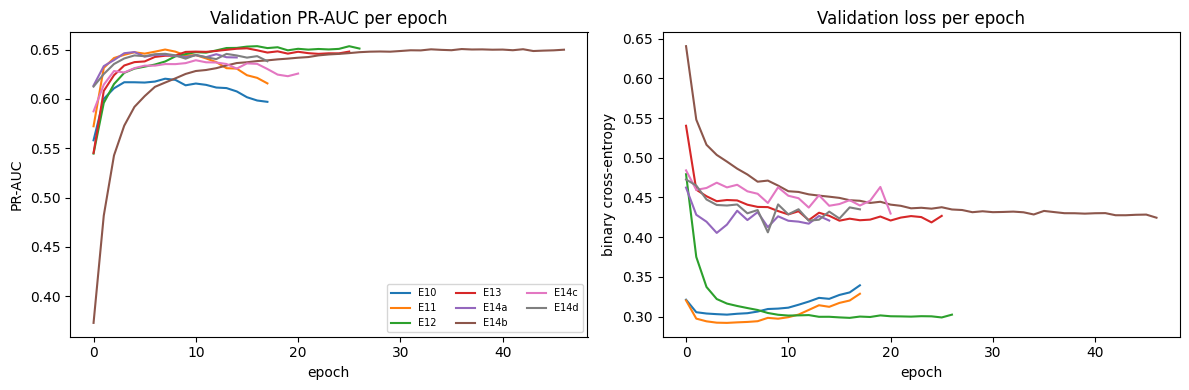

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for rid in [r["id"] for r in RESULTS if r["family"] == "Deep learning"]:
    h = ART[rid]["history"]; ax[0].plot(h["val_pr_auc"], label=rid); ax[1].plot(h["val_loss"], label=rid)
ax[0].set(title="Validation PR-AUC per epoch", xlabel="epoch", ylabel="PR-AUC")
ax[1].set(title="Validation loss per epoch", xlabel="epoch", ylabel="binary cross-entropy")
ax[0].legend(ncol=3, fontsize=7); fig.tight_layout()
fig.savefig("figures/keras_all_runs.png", dpi=200, bbox_inches="tight"); plt.show()

### What this output tells us
* **A plain network is barely better than logistic regression.** The Sequential MLP (E10) reaches 0.621, against 0.618 for E4. Adding a learned **country embedding** (E11, Functional API) lifts it to **0.650**, because 184 countries are represented more richly than the top-25 one-hot.
* **Unregularised networks overfit quickly.** E10 and E11 peak at epoch 8. In the right-hand plot their validation loss then *rises* while training continues.
* **Regularisation fixes this.** Dropout, L2 and batch normalisation (E12) give the **best network (0.654)**: the gap falls from 0.092 to 0.069, and validation loss stays flat instead of rising.
* **Class weights (E13) change the threshold, not the ranking.** PR-AUC stays at 0.651, but recall at the default 0.5 threshold jumps to 0.79 while precision falls to 0.42. The higher validation loss of the weighted runs in the plot is expected, because the loss is computed without the weights.
* **Learning rate.** At **3e-3** (E14a) the model peaks at epoch 5, with a noisier curve and a slightly lower score (0.648). At **3e-4** (E14b) it needs 37 epochs to reach the same level (0.650): slower, no gain.
* **More capacity (E14c) overfits more (gap 0.100) and scores lower (0.641).** A smaller batch (E14d) gives no gain either. The limit is the information in the features, not the size of the network.

## 9. Experiment table
Generated from the logged runs. The `observation` column explains in one sentence **why** each result changed. The best model of each family is chosen by **validation PR-AUC**, never by test score.

In [ ]:
OBSERVATIONS = {  # one sentence per run: why the result changed
    'E0': "Always predicting 'learner' gives 83.9% test accuracy but PR-AUC equal to the 16.1% base rate and F1 of 0, which is why accuracy is not used to choose models.",
    'E1': 'Background alone reaches val PR-AUC 0.380 (2.3x the base rate): age, university subject and supporting dependents carry real signal.',
    'E2': 'Adding learning intensity gives the largest jump of the study (+0.195 to 0.575), driven by months of programming.',
    'E3': 'Adding the 18 learning-resource features adds 0.037 (0.612); professional resources such as Stack Overflow and Pluralsight separate developers from learners, partly because developers use them at work.',
    'E4': 'Adding the 19 community and mentorship features adds only 0.006 (0.618): once learning intensity and resources are known, event attendance is largely redundant for prediction.',
    'E4b': 'Collapsing the 70 multi-select columns into 5 counts loses 0.039: which resources people use matters, not how many.',
    'E4c': 'Removing the log transform loses 0.032: heavy-tailed hours, months and money distort a linear model.',
    'E5': 'Random forest improves to 0.645 by modelling interactions, but train PR-AUC 0.898 (gap 0.253) shows high variance.',
    'E6': 'Default histogram boosting gives the best traditional validation PR-AUC (0.666) with a smaller gap (0.128), because shallow trees are fitted sequentially on residuals.',
    'E7': 'Tuning picked strong regularisation (min_samples_leaf 150, L2 5, 15 leaves, lr 0.2, 500 iterations) and cut the gap to 0.082, but validation PR-AUC (0.663) did not beat the defaults: the top configurations differ by under 0.002, a plateau.',
    'E8': 'The RBF SVM (0.592) is worse than logistic regression and about 38x slower to train than default boosting (57 s vs 1.5 s), so it adds cost without benefit on these features.',
    'E10': 'A small Sequential MLP (0.621) only just beats logistic regression (0.618); validation PR-AUC peaked at epoch 8 and validation loss rose afterwards (overfitting).',
    'E11': 'Adding a learned 8-d country embedding lifts the network to 0.650 (+0.029): it captures country effects that the top-25 one-hot cannot; it still overfits after epoch 8.',
    'E12': 'Dropout, L2 and batch normalisation give the best network (0.654): the gap falls from 0.092 to 0.069 and validation loss stays flat instead of rising, so regularisation fixed the overfitting.',
    'E13': 'Class weights leave PR-AUC almost unchanged (0.651) because ranking does not change, but they move scores upward so recall at 0.5 jumps to 0.79 and precision falls to 0.42.',
    'E14a': 'A higher learning rate (3e-3) peaks early (best epoch 5) at a slightly lower PR-AUC (0.648) with noisier validation curves.',
    'E14b': 'A lower learning rate (3e-4) needs 37 epochs to reach the same PR-AUC (0.650): slower, no gain.',
    'E14c': 'A wider and deeper network (256-128-64) overfits more (gap 0.100) and scores lower (0.641): capacity is not the bottleneck.',
    'E14d': 'Batch size 64 adds gradient noise and four times more updates per epoch but no gain (0.646).',
    'E15': 'Removing gender from the inputs keeps accuracy (0.664) and narrows the out-of-fold recall gap for women from -0.060 to -0.044, but does not close it: other features carry the same signal.',
    'E16': "Reweighting gender x age cells costs 0.062 PR-AUC (0.604) and the women's gap gets wider (-0.081), because reweighting shifts scores rather than improving the ranking inside the women's group.",
}
res = pd.DataFrame(RESULTS); res["observation"] = res["id"].map(OBSERVATIONS).fillna("")
res.to_csv("experiment_table.csv", index=False)
show = ["id", "builds_on", "model", "features", "train_pr_auc", "val_pr_auc", "test_pr_auc", "pr_auc_gap",
        "test_roc_auc", "val_f1", "test_f1", "test_recall", "test_precision", "seconds"]
with pd.option_context("display.max_colwidth", 45, "display.width", 250):
    display(res[show].round(3))
eligible = res[res.id != "E0"]
BEST_ML = eligible[eligible.family == "Traditional ML"].sort_values("val_pr_auc", ascending=False).iloc[0]["id"]
BEST_DL = eligible[eligible.family == "Deep learning"].sort_values("val_pr_auc", ascending=False).iloc[0]["id"]
NAME = res.set_index("id")["model"]
print("Best traditional (validation PR-AUC):", BEST_ML, NAME[BEST_ML], "| best deep:", BEST_DL, NAME[BEST_DL])

,id,builds_on,model,features,train_pr_auc,val_pr_auc,test_pr_auc,pr_auc_gap,test_roc_auc,val_f1,test_f1,test_recall,test_precision,seconds
0,E0,-,Base-rate baseline,none,0.165,0.165,0.161,0.001,0.500,0.000,0.000,0.000,0.000,0.2
1,E1,E0,Logistic regression: background,background,0.416,0.380,0.368,0.036,0.729,0.421,0.401,0.652,0.290,0.8
2,E2,E1,Logistic regression: + learning intensity,background + learning intensity,0.586,0.575,0.561,0.011,0.855,0.540,0.517,0.779,0.386,0.8
3,E3,E2,Logistic regression: + resources,+ learning resources,0.635,0.612,0.613,0.023,0.872,0.569,0.535,0.786,0.406,1.0
4,E4,E3,Logistic regression: + community & mentor...,all features,0.643,0.618,0.615,0.025,0.872,0.575,0.537,0.781,0.409,1.3
5,E4b,E4,Logistic regression: multi-selects as counts,"all, multi-selects as counts",0.595,0.579,0.561,0.016,0.856,0.540,0.524,0.775,0.396,1.0
6,E4c,E4,Logistic regression: no log/cap,"all features, raw skewed values",0.598,0.586,0.570,0.013,0.856,0.558,0.531,0.754,0.410,1.2
7,E5,E4,Random forest,all features,0.898,0.645,0.628,0.253,0.882,0.592,0.587,0.669,0.523,6.0
8,E6,E5,Histogram gradient boosting (defaults),all features,0.794,0.666,0.654,0.128,0.887,0.561,0.563,0.478,0.684,1.5
9,E7,E6,Histogram gradient boosting (tuned),all features,0.745,0.663,0.661,0.082,0.889,0.566,0.569,0.487,0.685,0.2


Best traditional (validation PR-AUC): E6 Histogram gradient boosting (defaults) | best deep: E12 + dropout 0.3, L2 1e-4, batch norm


### TensorBoard and W&B logs behind the table
Every number in the table above was also written to TensorBoard (and to an offline W&B run) at the moment each experiment ran. The next cell **reads the log files back** and checks that they match the table, then plots the per-epoch validation curves stored by the Keras TensorBoard callback. In Colab it also opens the interactive **TensorBoard dashboard** below the cell (use the *Scalars* tab; run names = experiment IDs). Locally, run `tensorboard --logdir logs` in a terminal.

,id,val PR-AUC in TensorBoard,val PR-AUC in table,test PR-AUC in TensorBoard,test PR-AUC in table,match
0,E0,0.1647,0.1647,0.1609,0.1609,True
1,E1,0.3800,0.3800,0.3679,0.3679,True
2,E2,0.5749,0.5749,0.5608,0.5608,True
3,E3,0.6119,0.6119,0.6131,0.6131,True
4,E4,0.6179,0.6179,0.6146,0.6146,True
5,E4b,0.5794,0.5794,0.5608,0.5608,True
6,E4c,0.5856,0.5856,0.5702,0.5702,True
7,E5,0.6453,0.6453,0.6282,0.6282,True
8,E6,0.6664,0.6664,0.6536,0.6536,True
9,E7,0.6629,0.6629,0.6607,0.6607,True


All table values match the TensorBoard logs: True


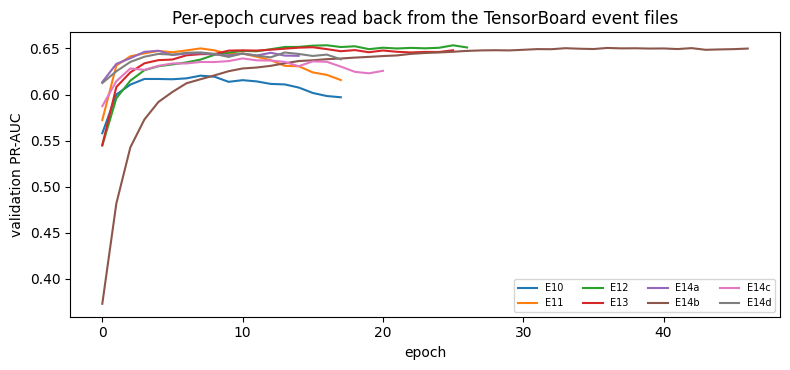

W&B offline runs: 19 | to upload them later: wandb sync wandb/offline-run-*
Interactive dashboard: run  tensorboard --logdir logs  and open http://localhost:6006


In [ ]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
def tb_values(path, tag):
    ea = EventAccumulator(path, size_guidance={"tensors": 0}); ea.Reload()
    return [float(tf.make_ndarray(e.tensor_proto)) for e in ea.Tensors(tag)] if tag in ea.Tags()["tensors"] else []

check = []
for rid in res.id:
    v, t_ = tb_values(f"logs/summary/{rid}", "val_pr_auc"), tb_values(f"logs/summary/{rid}", "test_pr_auc")
    check.append({"id": rid, "val PR-AUC in TensorBoard": v[0], "val PR-AUC in table": res.set_index("id").loc[rid, "val_pr_auc"],
                  "test PR-AUC in TensorBoard": t_[0], "test PR-AUC in table": res.set_index("id").loc[rid, "test_pr_auc"]})
TB_CHECK = pd.DataFrame(check)
TB_CHECK["match"] = np.isclose(TB_CHECK.iloc[:, 1], TB_CHECK.iloc[:, 2], atol=1e-6) & np.isclose(TB_CHECK.iloc[:, 3], TB_CHECK.iloc[:, 4], atol=1e-6)
display(TB_CHECK.round(4))
print("All table values match the TensorBoard logs:", bool(TB_CHECK["match"].all()))

fig, ax = plt.subplots(figsize=(8, 3.8))
for rid in [r for r in res.id if os.path.isdir(f"logs/{r}/validation")]:
    ax.plot(tb_values(f"logs/{rid}/validation", "epoch_pr_auc"), label=rid)
ax.set(xlabel="epoch", ylabel="validation PR-AUC", title="Per-epoch curves read back from the TensorBoard event files")
ax.legend(ncol=4, fontsize=7); fig.tight_layout(); fig.savefig("figures/tensorboard_readback.png", dpi=200, bbox_inches="tight"); plt.show()
print("W&B offline runs:", len([d for d in os.listdir("wandb") if d.startswith("offline-run")]) if os.path.isdir("wandb") else 0,
      "| to upload them later: wandb sync wandb/offline-run-*")

if IN_COLAB:
    get_ipython().run_line_magic("load_ext", "tensorboard")
    get_ipython().run_line_magic("tensorboard", "--logdir logs")
else:
    print("Interactive dashboard: run  tensorboard --logdir logs  and open http://localhost:6006")

### Is the difference between the finalists real?
(1) The best network is retrained with three more seeds to measure run-to-run noise. (2) The test set is bootstrapped 1,000 times for a 95% interval on the PR-AUC difference between the two finalists.

In [ ]:
a = ART[BEST_DL]; seed_scores = []
seq = a["builder"] is build_sequential
for sd in (1, 2, 3):
    tf.keras.utils.set_random_seed(sd); m = a["builder"](**a["cfg"])
    m.fit(make_ds("train", a["batch"], True, not seq), validation_data=make_ds("val", 1024, False, not seq),
          epochs=3 if QUICK_TEST else 80, class_weight=a["cw"], verbose=0,
          callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=10, restore_best_weights=True)])
    inp = ARR["test"] if seq else {"tab": ARR["test"], "country": CTRY["test"]}
    seed_scores.append(average_precision_score(Y["test"], m.predict(inp, batch_size=2048, verbose=0).ravel()))
print(f"{BEST_DL} test PR-AUC over seeds 1-3: mean {np.mean(seed_scores):.3f}, std {np.std(seed_scores):.3f}, values {np.round(seed_scores, 3)}")

def boot(fn, n=200 if QUICK_TEST else 1000, seed=SEED):
    rng = np.random.RandomState(seed); yt = Y["test"]; out = []
    for _ in range(n):
        i = rng.randint(0, len(yt), len(yt)); out.append(fn(i))
    return np.percentile(out, [2.5, 97.5])
pm, pd_ = PREDS[BEST_ML]["test"], PREDS[BEST_DL]["test"]
diff = average_precision_score(Y["test"], pm) - average_precision_score(Y["test"], pd_)
lo, hi = boot(lambda i: average_precision_score(Y["test"][i], pm[i]) - average_precision_score(Y["test"][i], pd_[i]))
print(f"Test PR-AUC, {BEST_ML} minus {BEST_DL}: {diff:+.3f}, bootstrap 95% CI [{lo:+.3f}, {hi:+.3f}]")

E12 test PR-AUC over seeds 1-3: mean 0.635, std 0.006, values [0.629 0.643 0.632]


Test PR-AUC, E6 minus E12: +0.025, bootstrap 95% CI [+0.008, +0.042]


### What this output tells us
* **The best network's score varies a little with the random seed:** three new seeds give test PR-AUC **0.635 ± 0.006** (0.629–0.643).
* **Default gradient boosting (E6) beats the best network (E12) by +0.025 test PR-AUC**, with a bootstrap 95% CI of **[+0.008, +0.042]**. The interval excludes zero, so the advantage is small but real.
* **This matches benchmark studies:** tree ensembles tend to beat neural networks on medium-sized tabular data (Grinsztajn et al., 2022; Shwartz-Ziv & Armon, 2022).
* **Trade-offs also favour E6:** it trains in about 1.5 seconds, its feature importances are directly inspectable, and its predicted probabilities are slightly better calibrated (Brier 0.087 vs 0.090).

## 10. Evaluation figures
**Decision threshold.** A 0.5 cut-off is arbitrary for an imbalanced problem, so for each finalist the threshold that maximises F1 is chosen **on the validation set** and then applied unchanged to the test set. Confusion matrices use that threshold.

Validation-chosen thresholds: {'E6': 0.289, 'E12': 0.259}


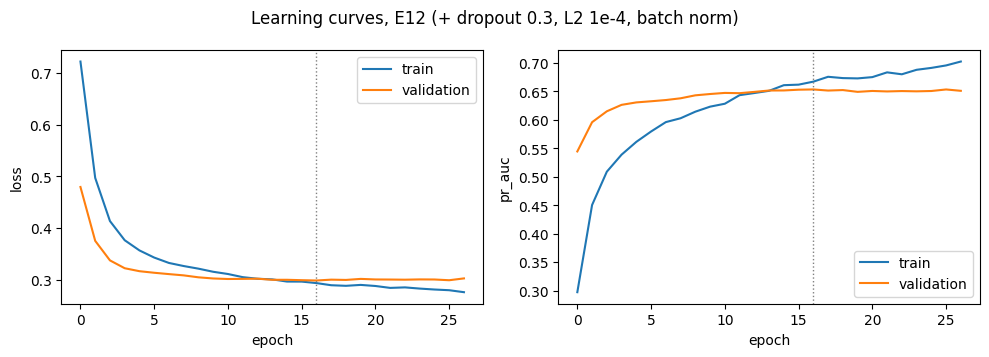

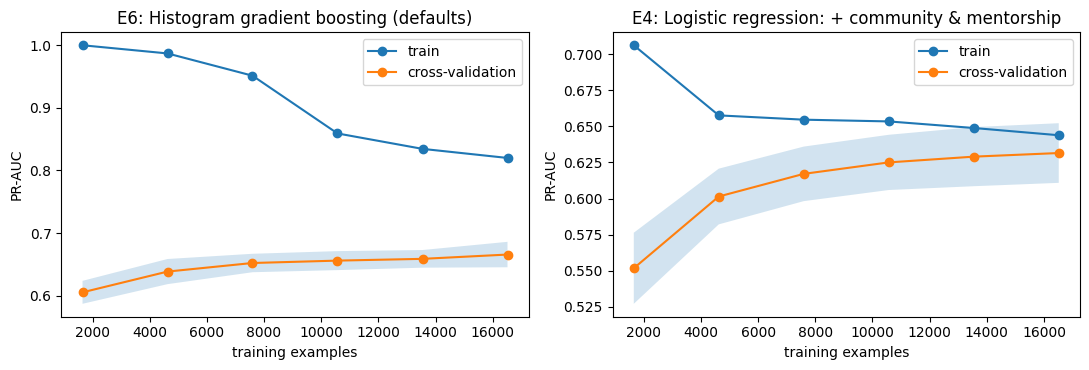

E6


,n,train,cv,cv_std
0,1651,1.000,0.606,0.018
1,4624,0.987,0.639,0.020
2,7596,0.951,0.652,0.015
3,10569,0.859,0.656,0.015
4,13542,0.834,0.659,0.014
5,16515,0.820,0.666,0.020


E4


,n,train,cv,cv_std
0,1651,0.706,0.552,0.025
1,4624,0.658,0.601,0.019
2,7596,0.655,0.617,0.019
3,10569,0.654,0.625,0.019
4,13542,0.649,0.629,0.021
5,16515,0.644,0.632,0.021


In [ ]:
def save(fig, name): fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
THR = {}
for rid in (BEST_ML, BEST_DL):
    p, r, t = precision_recall_curve(Y["val"], PREDS[rid]["val"]); f = 2 * p * r / np.clip(p + r, 1e-9, None)
    THR[rid] = float(t[np.argmax(f[:-1])])
print("Validation-chosen thresholds:", {k: round(v, 3) for k, v in THR.items()})

# (a) Keras epoch curves
h = ART[BEST_DL]["history"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a_, k in zip(ax, ("loss", "pr_auc")):
    a_.plot(h[k], label="train"); a_.plot(h["val_" + k], label="validation"); a_.set(xlabel="epoch", ylabel=k); a_.legend()
    a_.axvline(int(np.argmax(h["val_pr_auc"])), color="grey", ls=":", lw=1)
fig.suptitle(f"Learning curves, {BEST_DL} ({NAME[BEST_DL]})"); fig.tight_layout(); save(fig, "learning_curves_keras"); plt.show()

# (b) training-set-size learning curves
LC = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for a_, rid in zip(axes, (BEST_ML, "E4")):
    sizes, tr_sc, va_sc = learning_curve(clone(ART[rid]["model"]), SPLITS["train"][ART[rid]["cols"]], Y["train"],
                                         groups=GROUPS["train"], cv=StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED),
                                         train_sizes=np.linspace(0.1, 1.0, 3 if QUICK_TEST else 6), scoring="average_precision", n_jobs=-1)
    LC[rid] = pd.DataFrame({"n": sizes, "train": tr_sc.mean(1), "cv": va_sc.mean(1), "cv_std": va_sc.std(1)})
    a_.plot(sizes, tr_sc.mean(1), "o-", label="train"); a_.plot(sizes, va_sc.mean(1), "o-", label="cross-validation")
    a_.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.2)
    a_.set(xlabel="training examples", ylabel="PR-AUC", title=f"{rid}: {NAME[rid]}"); a_.legend()
fig.tight_layout(); save(fig, "learning_curve_sklearn"); plt.show()
for rid, t_ in LC.items(): print(rid); display(t_.round(3))

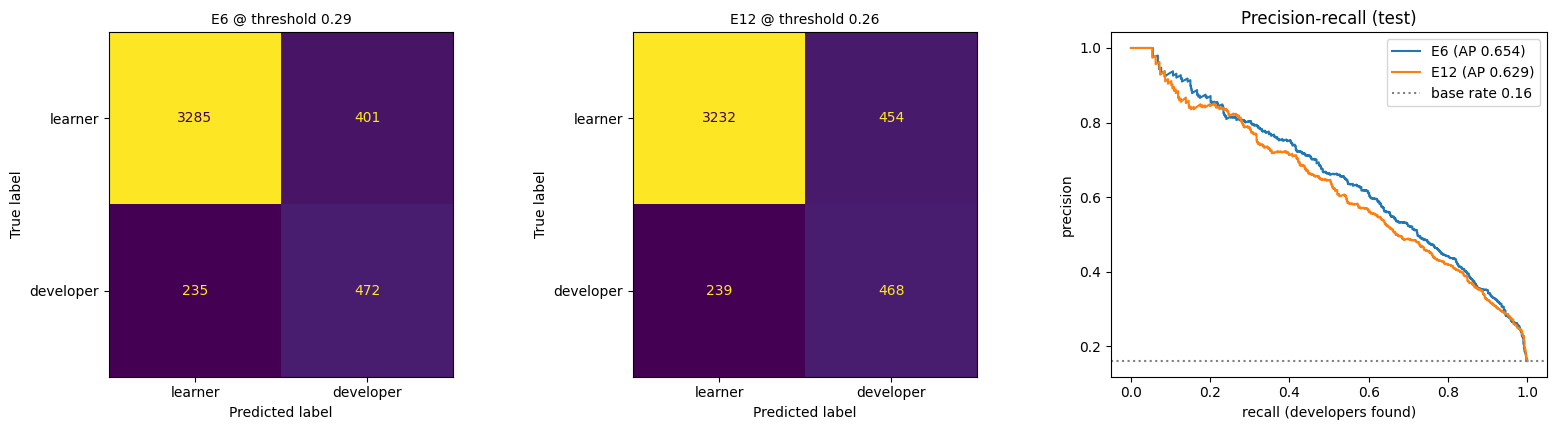

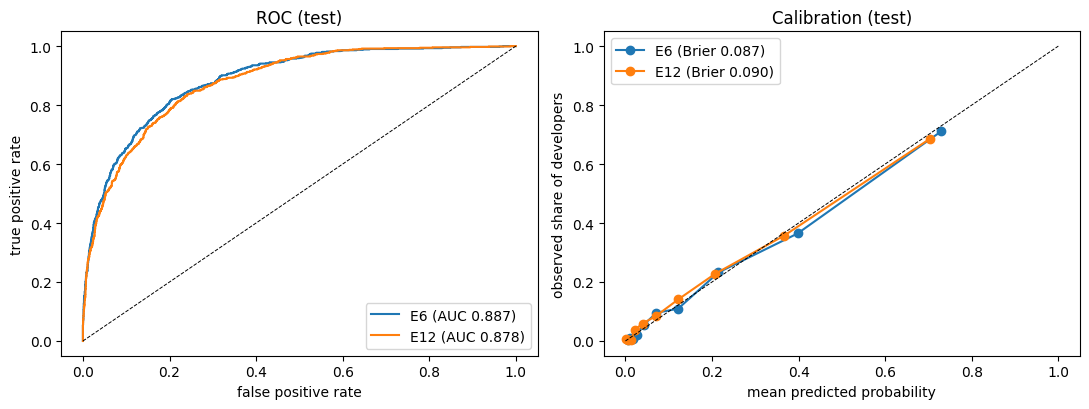


E6 (Histogram gradient boosting (defaults)) at validation-chosen threshold 0.289
              precision    recall  f1-score   support

     learner      0.933     0.891     0.912      3686
   developer      0.541     0.668     0.597       707

    accuracy                          0.855      4393
   macro avg      0.737     0.779     0.755      4393
weighted avg      0.870     0.855     0.861      4393


E12 (+ dropout 0.3, L2 1e-4, batch norm) at validation-chosen threshold 0.259
              precision    recall  f1-score   support

     learner      0.931     0.877     0.903      3686
   developer      0.508     0.662     0.575       707

    accuracy                          0.842      4393
   macro avg      0.719     0.769     0.739      4393
weighted avg      0.863     0.842     0.850      4393



In [ ]:
yt = Y["test"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for i, rid in enumerate((BEST_ML, BEST_DL)):
    pred = (PREDS[rid]["test"] >= THR[rid]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(yt, pred), display_labels=["learner", "developer"]).plot(
        ax=axes[i], colorbar=False, values_format="d")
    axes[i].set_title(f"{rid} @ threshold {THR[rid]:.2f}", fontsize=10)
for rid in (BEST_ML, BEST_DL):
    p, r, _ = precision_recall_curve(yt, PREDS[rid]["test"])
    axes[2].plot(r, p, label=f"{rid} (AP {average_precision_score(yt, PREDS[rid]['test']):.3f})")
axes[2].axhline(yt.mean(), color="grey", ls=":", label=f"base rate {yt.mean():.2f}")
axes[2].set(xlabel="recall (developers found)", ylabel="precision", title="Precision-recall (test)"); axes[2].legend()
fig.tight_layout(); save(fig, "confusion_pr"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for rid in (BEST_ML, BEST_DL):
    fpr, tpr, _ = roc_curve(yt, PREDS[rid]["test"]); axes[0].plot(fpr, tpr, label=f"{rid} (AUC {roc_auc_score(yt, PREDS[rid]['test']):.3f})")
    frac, mean_p = calibration_curve(yt, PREDS[rid]["test"], n_bins=10, strategy="quantile")
    axes[1].plot(mean_p, frac, "o-", label=f"{rid} (Brier {brier_score_loss(yt, PREDS[rid]['test']):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.7); axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC (test)"); axes[0].legend()
axes[1].plot([0, 1], [0, 1], "k--", lw=0.7); axes[1].set(xlabel="mean predicted probability", ylabel="observed share of developers", title="Calibration (test)"); axes[1].legend()
fig.tight_layout(); save(fig, "roc_calibration"); plt.show()

for rid in (BEST_ML, BEST_DL):
    print(f"\n{rid} ({NAME[rid]}) at validation-chosen threshold {THR[rid]:.3f}")
    print(classification_report(yt, (PREDS[rid]["test"] >= THR[rid]).astype(int), target_names=["learner", "developer"], digits=3))

### What this output tells us
**Learning curves**
* **E12 (Keras):** training loss starts *above* validation loss because dropout and L2 are active only during training. The curves cross around epoch 12. Validation PR-AUC plateaus near 0.65 from about epoch 8 while training PR-AUC keeps rising towards 0.70. This is mild, late overfitting, which early stopping limits by keeping the best epoch (17).
* **E6 (boosting):** with small training sets, training PR-AUC is 1.0 while cross-validated PR-AUC is 0.61, so the model memorises. As data grows, training falls to **0.820** and CV rises to **0.666**. The gap narrows but the curves have not met: a **variance-limited model that would still gain from more data**.
* **E4 (logistic regression):** training (0.644) and CV (0.632) are almost equal and nearly flat. This is **high bias**: more data won't help a linear model, only a more flexible one would.

**Confusion matrices** (thresholds chosen on validation: E6 0.289, E12 0.259)
* E6 finds **472 of 707 developers** (recall 0.668), misses **235**, and raises **401 false alarms** among 3,686 learners (precision 0.541).
* E12 makes a similar trade-off with lower precision (recall 0.662, precision 0.508).

**ROC, precision–recall and calibration**
* **ROC-AUC looks excellent (0.887 for E6)** because the 3,686 learners make the false-positive rate small.
* **The PR curves are more honest:** average precision is **0.654**, and precision falls steadily as recall rises. With a 16.1% base rate, ROC-AUC flatters the model (Saito & Rehmsmeier, 2015).
* **Both models are well calibrated:** points lie close to the diagonal (Brier 0.087 vs 0.090), with slight over-prediction in the upper deciles.

## 11. Error analysis
1. **What drives the best traditional model?** Permutation importance on the validation set, grouped by feature group and by single feature (drop in PR-AUC when the column is shuffled).
2. **Who is misclassified?** Error profiles of false negatives (developers the model calls learners) and false positives (learners called developers).
3. **What does this mean for a programme?** Precision and recall of the "job-ready" flag at different thresholds.

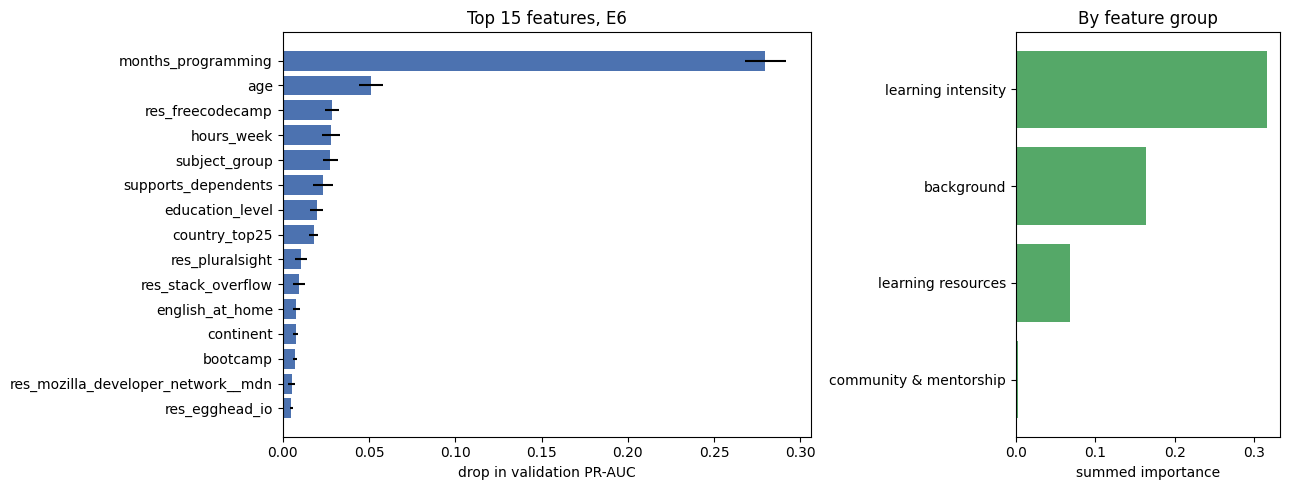

,feature,importance,std,group
18,months_programming,0.2796,0.0120,learning intensity
6,age,0.0511,0.0070,background
21,res_freecodecamp,0.0284,0.0039,learning resources
17,hours_week,0.0279,0.0052,learning intensity
4,subject_group,0.0276,0.0042,background
11,supports_dependents,0.0233,0.0056,background
10,education_level,0.0196,0.0035,background
2,country_top25,0.0179,0.0026,background
27,res_pluralsight,0.0106,0.0034,learning resources
23,res_stack_overflow,0.0095,0.0035,learning resources


In [ ]:
best_pipe, best_cols = ART[BEST_ML]["model"], ART[BEST_ML]["cols"]
pi = permutation_importance(best_pipe, SPLITS["val"][best_cols], Y["val"], scoring="average_precision",
                            n_repeats=3 if QUICK_TEST else 10, random_state=SEED, n_jobs=-1)
IMP = pd.DataFrame({"feature": best_cols, "importance": pi.importances_mean, "std": pi.importances_std})
group_of = lambda c: ("background" if c in BG_CAT + BG_NUM else "learning intensity" if c in LEARN_NUM else
                      "learning resources" if c in RES_NUM else "community & mentorship")
IMP["group"] = IMP.feature.map(group_of)
top = IMP.sort_values("importance", ascending=False).head(15).iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].barh(top.feature, top.importance, xerr=top["std"], color="#4C72B0"); ax[0].set(xlabel="drop in validation PR-AUC", title=f"Top 15 features, {BEST_ML}")
gsum = IMP.groupby("group").importance.sum().sort_values()
ax[1].barh(gsum.index, gsum.values, color="#55A868"); ax[1].set(xlabel="summed importance", title="By feature group")
fig.tight_layout(); save(fig, "permutation_importance"); plt.show()
display(IMP.sort_values("importance", ascending=False).head(15).round(4))

In [ ]:
T = SPLITS["test"].copy(); T["y"] = Y["test"]; T["p"] = PREDS[BEST_ML]["test"]; T["pred"] = (T.p >= THR[BEST_ML]).astype(int)
T["outcome"] = np.select([(T.y == 1) & (T.pred == 1), (T.y == 1) & (T.pred == 0), (T.y == 0) & (T.pred == 1)],
                         ["true positive", "false negative", "false positive"], "true negative")
prof = T.groupby("outcome").agg(n=("y", "size"), months_programming=("months_programming", "median"),
                                hours_week=("hours_week", "median"), age=("age", "median"),
                                share_women=("gender", lambda s: (s == "Female").mean()),
                                computing_degree=("subject_group", lambda s: (s == "computing").mean()),
                                n_events=("n_events", "mean"), used_stack_overflow=("res_stack_overflow", "mean"))
display(prof.round(2))
print("Error rate by months-programming band:")
T["experience"] = pd.cut(T.months_programming, [-1, 6, 24, 60, 1000], labels=["0-6 m", "7-24 m", "25-60 m", "60+ m"])
display(T.groupby("experience", observed=True)[["y", "pred"]].apply(lambda g: pd.Series({"n": len(g), "share developers": g.y.mean(),
        "recall": g.pred[g.y == 1].mean() if (g.y == 1).any() else np.nan, "false positive rate": g.pred[g.y == 0].mean()})).round(3))

rows = []
for t_ in (0.3, 0.4, 0.5, 0.6, 0.7, THR[BEST_ML]):
    f = (T.p >= t_).astype(int)
    rows.append({"threshold": round(t_, 3), "recall": recall_score(T.y, f), "precision": precision_score(T.y, f, zero_division=0),
                 "flagged share": f.mean()})
THRESH_TABLE = pd.DataFrame(rows).drop_duplicates("threshold").sort_values("threshold"); display(THRESH_TABLE.round(3))

,n,months_programming,hours_week,age,share_women,computing_degree,n_events,used_stack_overflow
outcome,,,,,,,,
false negative,235,12.0,12.0,25.5,0.20,0.29,0.53,0.56
false positive,401,24.0,10.0,28.0,0.14,0.53,0.91,0.75
true negative,3285,3.0,10.0,26.0,0.22,0.16,0.38,0.36
true positive,472,36.0,8.0,27.0,0.12,0.58,0.87,0.80


Error rate by months-programming band:


,n,share developers,recall,false positive rate
experience,,,,
0-6 m,2276.0,0.046,0.135,0.014
7-24 m,1167.0,0.219,0.648,0.210
25-60 m,494.0,0.447,0.846,0.498
60+ m,142.0,0.662,0.979,0.771


,threshold,recall,precision,flagged share
5,0.289,0.668,0.541,0.199
0,0.300,0.661,0.547,0.194
1,0.400,0.567,0.632,0.144
2,0.500,0.478,0.684,0.112
3,0.600,0.385,0.753,0.082
4,0.700,0.284,0.807,0.057


### What this output tells us
**What drives the model**
* **Months programming dominates:** shuffling it drops validation PR-AUC by **0.280**.
* **Next come** age (0.051), using freeCodeCamp (0.028), hours per week (0.028), university subject (0.028) and supporting dependents (0.023).
* **By group:** learning intensity matters most, then background, then resources. Community and mentorship add almost nothing, consistent with the ablation.
* **Gender is not among the top 15 features.** Yet the fairness audit shows a gap, which already hints that the gap comes from *other* features.

**Who is missed**
* **False negatives** (developers called learners) have a median of **12 months** of programming against **36** for correctly found developers.
* They hold computing degrees less often (29% vs 58%) and are **20% women**, against 12% among correctly found developers.
* **The model misses early-career developers and developers from non-traditional pathways, and women are concentrated there.**
* **Recall rises steeply with experience:** 13.5% at 0–6 months, 64.8% at 7–24, 84.6% at 25–60, 97.9% at 60+.

**Reverse causality.** Some features, such as using Stack Overflow or Pluralsight or supporting dependents, may be *consequences* of having a developer job (work tools, income). The model recognises a profile; it does not show what causes the transition.

**Threshold trade-off** (test set)

| Threshold | Recall | Precision | Share flagged |
|---|---|---|---|
| 0.289 (chosen) | 0.668 | 0.541 | 19.9% |
| 0.4 | 0.567 | 0.632 | 14.4% |
| 0.5 | 0.478 | 0.684 | 11.2% |
| 0.6 | 0.385 | 0.753 | 8.2% |

* A **mentorship programme** that wants to reach most job-ready learners should use about 0.3: it catches two-thirds, and about 46% of those flagged are not yet developers.
* A **placement programme with few slots** would choose 0.5–0.6 for higher precision.

## 12. Fairness audit: are women, and especially young women, recognised as reliably as men?
This section answers the research question. Groups compared:
* **all women vs all men** (respondents who did not state a gender are left out of this comparison only);
* **young women vs young men** (aged 18–25), the group named in the mission;
* **Africa** (women and young women living in Africa), reported **descriptively** with wide intervals because there are few African developers.

**"Recognised as reliably"** is measured four ways:
1. **Equal opportunity** (Hardt et al., 2016): *recall among people who really are developers*. If it is lower for women, the model misses women who have made it, so a programme using it would under-recommend them.
2. **Ranking quality inside each group**: PR-AUC and ROC-AUC, plus **ABROCA** (Gardner et al., 2019), the area between two groups' ROC curves.
3. **Calibration**: the average predicted probability for developers in each group. A lower value for women developers means the model systematically *under-scores* them.
4. **Selection rate** and **disparate impact** (Feldman et al., 2015). Base rates differ (fewer women are already developers), so equal selection rates are not expected; this is reported for completeness.

**Using every respondent (out-of-fold predictions).** The test set alone has few young women developers. So the best traditional model's configuration is also refit 7 times with `StratifiedGroupKFold`, and every respondent receives a prediction from a model that never saw them. All subgroup statistics below use these **out-of-fold (OOF)** predictions with 1,000-sample bootstrap 95% intervals. The decision threshold is the one chosen on the validation set in Section 10.

In [ ]:
# ---- out of fold predictions for every respondent (best traditional configuration) ----
XA = X_all.reset_index(drop=True); cols_best = ART[BEST_ML]["cols"]
OOF = np.zeros(len(XA)); t = time.time()
oof_cv = StratifiedGroupKFold(n_splits=3 if QUICK_TEST else 7, shuffle=True, random_state=SEED)
for tr, te_ in oof_cv.split(XA, y_all, groups_all):
    m = clone(ART[BEST_ML]["model"]).fit(XA.iloc[tr][cols_best], y_all[tr])
    OOF[te_] = m.predict_proba(XA.iloc[te_][cols_best])[:, 1]
print(f"OOF predictions for {len(OOF):,} respondents in {time.time() - t:.0f}s | OOF PR-AUC {average_precision_score(y_all, OOF):.3f}")

young = XA.age.between(18, 25).values
G_ = {"women": (XA.gender == "Female").values, "men": (XA.gender == "Male").values}
G_["young women"], G_["young men"] = G_["women"] & young, G_["men"] & young
afr_ = (XA.lives_in_africa == 1).values
G_["African women"], G_["African men"] = G_["women"] & afr_, G_["men"] & afr_
G_["young African women"], G_["young African men"] = G_["young women"] & afr_, G_["young men"] & afr_

def group_stats(m, y, p, thr):
    yy, pp = y[m], p[m]; f = pp >= thr
    return {"n": int(m.sum()), "developers": int(yy.sum()), "base_rate": yy.mean(),
            "recall (equal opp.)": f[yy == 1].mean() if yy.sum() else np.nan,
            "false_pos_rate": f[yy == 0].mean(), "selection_rate": f.mean(),
            "precision": yy[f].mean() if f.sum() else np.nan,
            "pr_auc": average_precision_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan,
            "roc_auc": roc_auc_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan,
            "mean_score_of_developers": pp[yy == 1].mean() if yy.sum() else np.nan}

def abroca(y, p, m1, m2):
    grid = np.linspace(0, 1, 1001); c = []
    for m in (m1, m2):
        fpr, tpr, _ = roc_curve(y[m], p[m]); c.append(np.interp(grid, fpr, tpr))
    return float(np.trapezoid(np.abs(c[0] - c[1]), grid))

def boot_gap(y, p, thr, m1, m2, stat="recall", n=200 if QUICK_TEST else 1000):
    # bootstrap the difference (group1 - group2), resampling respondents within each group
    rng = np.random.RandomState(SEED); i1, i2 = np.where(m1)[0], np.where(m2)[0]; out = []
    def val(idx):
        yy, pp = y[idx], p[idx]
        if stat == "recall": return (pp[yy == 1] >= thr).mean()
        if stat == "pr_auc": return average_precision_score(yy, pp)
        return pp[yy == 1].mean()
    for _ in range(n):
        out.append(val(rng.choice(i1, len(i1))) - val(rng.choice(i2, len(i2))))
    return val(i1) - val(i2), np.percentile(out, 2.5), np.percentile(out, 97.5)

thr = THR[BEST_ML]
FAIR = pd.DataFrame([{"group": g, **group_stats(m, y_all, OOF, thr)} for g, m in G_.items()])
FAIR.to_csv("fairness_groups_oof.csv", index=False)
with pd.option_context("display.width", 250): display(FAIR.round(3))

rows = []
for a_, b_ in (("women", "men"), ("young women", "young men"), ("African women", "African men"), ("young African women", "young African men")):
    r = {"comparison": f"{a_} - {b_}", "n (group 1 developers)": int(y_all[G_[a_]].sum())}
    for stat in ("recall", "pr_auc", "mean_score"):
        d0, lo, hi = boot_gap(y_all, OOF, thr, G_[a_], G_[b_], stat)
        r[f"{stat} gap"] = d0; r[f"{stat} 95% CI"] = f"[{lo:+.3f}, {hi:+.3f}]"
    r["ABROCA"] = abroca(y_all, OOF, G_[a_], G_[b_])
    r["disparate impact"] = (OOF[G_[a_]] >= thr).mean() / (OOF[G_[b_]] >= thr).mean()
    rows.append(r)
GAPS = pd.DataFrame(rows); GAPS.to_csv("fairness_gaps_oof.csv", index=False)
with pd.option_context("display.width", 250, "display.max_colwidth", 30): display(GAPS.round(3))

OOF predictions for 30,843 respondents in 20s | OOF PR-AUC 0.668


,group,n,developers,base_rate,recall (equal opp.),false_pos_rate,selection_rate,precision,pr_auc,roc_auc,mean_score_of_developers
0,women,6259,675,0.108,0.634,0.060,0.122,0.559,0.614,0.906,0.428
1,men,23486,4203,0.179,0.695,0.113,0.217,0.573,0.681,0.889,0.490
2,young women,2160,247,0.114,0.587,0.065,0.125,0.539,0.561,0.877,0.388
3,young men,9894,1704,0.172,0.627,0.113,0.202,0.535,0.618,0.864,0.433
4,African women,323,39,0.121,0.641,0.046,0.118,0.658,0.669,0.869,0.400
5,African men,1813,258,0.142,0.566,0.118,0.182,0.442,0.512,0.839,0.383
6,young African women,173,17,0.098,0.529,0.058,0.104,0.500,0.452,0.744,0.301
7,young African men,927,136,0.147,0.478,0.121,0.174,0.404,0.423,0.793,0.316


,comparison,n (group 1 developers),recall gap,recall 95% CI,pr_auc gap,pr_auc 95% CI,mean_score gap,mean_score 95% CI,ABROCA,disparate impact
0,women - men,675,-0.060,"[-0.100, -0.023]",-0.067,"[-0.109, -0.025]",-0.062,"[-0.085, -0.040]",0.017,0.564
1,young women - young men,247,-0.040,"[-0.111, +0.020]",-0.057,"[-0.125, +0.009]",-0.045,"[-0.081, -0.014]",0.019,0.617
2,African women - African men,39,0.075,"[-0.097, +0.227]",0.157,"[-0.004, +0.292]",0.017,"[-0.081, +0.109]",0.057,0.646
3,young African women - youn...,17,0.051,"[-0.204, +0.304]",0.028,"[-0.205, +0.271]",-0.015,"[-0.146, +0.114]",0.091,0.599


### Is the gap explained by experience?
Women in the survey may have programmed for fewer months. If the recall gap disappears when women and men **with the same experience** are compared, the model is reflecting different experience, not treating women differently. Recall among developers is compared within experience bands.

In [ ]:
band = pd.cut(XA.months_programming, [-1, 12, 36, 84, 1000], labels=["0-12 m", "13-36 m", "37-84 m", "85+ m"])
rows = []
for b in band.cat.categories:
    inb = (band == b).values
    for g in ("women", "men", "young women", "young men"):
        m = G_[g] & inb & (y_all == 1)
        rows.append({"experience": b, "group": g, "developers": int(m.sum()),
                     "recall": (OOF[m] >= thr).mean() if m.sum() else np.nan, "mean score": OOF[m].mean() if m.sum() else np.nan})
EXP = pd.DataFrame(rows)
display(EXP.pivot(index="experience", columns="group", values=["developers", "recall", "mean score"]).round(3))
print("Median months programming among developers: women",
      np.nanmedian(XA.months_programming[G_["women"] & (y_all == 1)]), "| men", np.nanmedian(XA.months_programming[G_["men"] & (y_all == 1)]))

developers                              recall                   \
group             men  women young men young women    men  women young men   
experience                                                                   
0-12 m         1223.0  219.0     619.0       102.0  0.357  0.333     0.354   
13-36 m        1478.0  256.0     703.0        97.0  0.773  0.734     0.768   
37-84 m         865.0  118.0     308.0        33.0  0.913  0.915     0.847   
85+ m           503.0   49.0      37.0         4.0  0.984  0.959     0.865   

                       mean score                               
group      young women        men  women young men young women  
experience                                                      
0-12 m           0.382      0.254  0.237     0.257       0.262  
13-36 m          0.742      0.513  0.463     0.529       0.479  
37-84 m          0.818      0.658  0.625     0.573       0.527  
85+ m            0.750      0.760  0.746     0.541       0.669

Median months programming among developers: women 24.0 | men 24.0


### How stable are the gaps? (5 different random splits)
A single split can be lucky or unlucky, especially for small groups such as young women developers (247 people). The out-of-fold audit is therefore repeated with **5 different random fold assignments** (seeds 101–105). For each, the women − men and young women − young men recall gaps are recomputed with their bootstrap 95% intervals. A result is called *robust* only if it holds in most repetitions.

In [ ]:
ROB = []
for s_ in range(101, 106):
    cv_s = StratifiedGroupKFold(n_splits=3 if QUICK_TEST else 7, shuffle=True, random_state=s_)
    oof_s = np.zeros(len(XA))
    for tr, te_ in cv_s.split(XA, y_all, groups_all):
        m = clone(ART[BEST_ML]["model"]).fit(XA.iloc[tr][cols_best], y_all[tr])
        oof_s[te_] = m.predict_proba(XA.iloc[te_][cols_best])[:, 1]
    row = {"split seed": s_, "OOF PR-AUC": average_precision_score(y_all, oof_s)}
    for lab, a_, b_ in (("women - men", "women", "men"), ("young women - young men", "young women", "young men")):
        d0, lo, hi = boot_gap(y_all, oof_s, thr, G_[a_], G_[b_], "recall", n=200 if QUICK_TEST else 1000)
        row[f"{lab} gap"] = d0; row[f"{lab} 95% CI"] = f"[{lo:+.3f}, {hi:+.3f}]"; row[f"{lab} CI excludes 0"] = bool(hi < 0 or lo > 0)
    ROB.append(row)
ROB = pd.DataFrame(ROB); ROB.to_csv("fairness_robustness.csv", index=False)
with pd.option_context("display.width", 250): display(ROB.round(3))
for lab in ("women - men", "young women - young men"):
    print(f"{lab}: mean gap {ROB[lab + ' gap'].mean():+.3f} (range {ROB[lab + ' gap'].min():+.3f} to {ROB[lab + ' gap'].max():+.3f}); "
          f"CI excludes zero in {int(ROB[lab + ' CI excludes 0'].sum())} of {len(ROB)} splits")

,split seed,OOF PR-AUC,women - men gap,women - men 95% CI,women - men CI excludes 0,young women - young men gap,young women - young men 95% CI,young women - young men CI excludes 0
0,101,0.674,-0.058,"[-0.096, -0.019]",True,-0.034,"[-0.097, +0.026]",False
1,102,0.673,-0.077,"[-0.116, -0.037]",True,-0.056,"[-0.123, +0.006]",False
2,103,0.674,-0.063,"[-0.102, -0.022]",True,-0.059,"[-0.123, +0.003]",False
3,104,0.672,-0.056,"[-0.096, -0.015]",True,-0.030,"[-0.092, +0.032]",False
4,105,0.672,-0.072,"[-0.109, -0.033]",True,-0.060,"[-0.128, -0.001]",True


women - men: mean gap -0.065 (range -0.077 to -0.056); CI excludes zero in 5 of 5 splits
young women - young men: mean gap -0.048 (range -0.060 to -0.030); CI excludes zero in 1 of 5 splits


### E15–E17: can the gap be reduced?
* **E15 – remove gender from the inputs** ("fairness through unawareness"). Same tuned configuration, `gender` dropped.
* **E16 – reweighting**: each gender × age-band cell gets the same total weight during training, so women and young women count as much as men.
* **E17 – group-specific thresholds** (post-processing): on the validation set, choose a separate threshold for women so that their recall matches men's, then apply it unchanged to the test set.

E15 and E16 are logged like every other run; E17 changes only the decision rule, so its effect is reported in the tables below and logged to TensorBoard/W&B. Each variant is evaluated twice: on the held-out test set (few women developers, so noisy) and on **all respondents** with out-of-fold predictions and bootstrap intervals (the reliable comparison).

In [ ]:
best_est = ART[BEST_ML]["model"].named_steps["model"]
NO_G = ([c for c in BG_CAT if c != "gender"], [c for c in FEATS_ALL[1]])
run_sk("E15", BEST_ML, clone(best_est), f"{NAME[BEST_ML]} without gender input", {"same as": BEST_ML, "dropped": "gender"},
       NO_G, "all features except gender", scale=False)

def balance_weights(d):
    ageband = pd.cut(d.age, [0, 25, 35, 200], labels=["<=25", "26-35", "36+"]).astype(object).fillna("age unknown")
    cell = d.gender.astype(str) + "|" + ageband.astype(str)
    cnt = cell.map(cell.value_counts()); return (len(d) / (cnt * cell.nunique())).values
pipe16 = Pipeline([("pre", preprocessor(FEATS_ALL, scale=False)), ("model", clone(best_est))])
pipe16.fit(SPLITS["train"][cols_all], Y["train"], model__sample_weight=balance_weights(SPLITS["train"]))
run_sk("E16", BEST_ML, None, f"{NAME[BEST_ML]} + gender x age reweighting", {"same as": BEST_ML, "sample_weight": "balanced gender x age band"},
       pipe=pipe16)

for rid in ("E15", "E16"):
    p, r, t_ = precision_recall_curve(Y["val"], PREDS[rid]["val"]); f = 2 * p * r / np.clip(p + r, 1e-9, None)
    THR[rid] = float(t_[np.argmax(f[:-1])])

# E17: group-specific threshold for women, chosen on validation to match men's validation recall
va, te = SPLITS["val"], SPLITS["test"]; pv, pt = PREDS[BEST_ML]["val"], PREDS[BEST_ML]["test"]
fv, mv = (va.gender == "Female").values, (va.gender == "Male").values
target = (pv[mv & (Y["val"] == 1)] >= THR[BEST_ML]).mean()
cands = np.linspace(0.05, 0.95, 181)
thr_w = cands[np.argmin([abs((pv[fv & (Y["val"] == 1)] >= c).mean() - target) for c in cands])]
print(f"E17 thresholds: men {THR[BEST_ML]:.3f}, women {thr_w:.3f} (chosen on validation)")

def test_fair(p, thr_women, thr_men):
    ft, mt, yt = (te.gender == "Female").values, (te.gender == "Male").values, Y["test"]
    yf, ym = te.age.between(18, 25).values & ft, te.age.between(18, 25).values & mt
    flag = np.where(ft, p >= thr_women, p >= thr_men)
    rec = lambda m: flag[m & (yt == 1)].mean()
    return {"test PR-AUC": average_precision_score(yt, p), "test F1": f1_score(yt, flag), "test precision": precision_score(yt, flag),
            "recall women": rec(ft), "recall men": rec(mt), "recall gap F-M": rec(ft) - rec(mt),
            "recall young women": rec(yf), "recall young men": rec(ym), "recall gap young F-M": rec(yf) - rec(ym),
            "flagged share": flag.mean()}
MIT = pd.DataFrame({
    f"{BEST_ML} (baseline)": test_fair(pt, THR[BEST_ML], THR[BEST_ML]),
    "E15 no gender input": test_fair(PREDS["E15"]["test"], THR["E15"], THR["E15"]),
    "E16 reweighting": test_fair(PREDS["E16"]["test"], THR["E16"], THR["E16"]),
    "E17 group threshold": test_fair(pt, thr_w, THR[BEST_ML])}).T
MIT.to_csv("fairness_mitigation_test.csv")
print(f"Test set only ({int(((te.gender == 'Female').values & (Y['test'] == 1)).sum())} women developers, "
      f"{int((te.age.between(18, 25).values & (te.gender == 'Female').values & (Y['test'] == 1)).sum())} young women developers) - noisy:")
display(MIT.round(3))

# Same comparison on ALL respondents with out-of-fold predictions and bootstrap intervals (the reliable version)
def oof_for(make_pipe, cols, weights_fn=None):
    out = np.zeros(len(XA))
    for tr, te_ in oof_cv.split(XA, y_all, groups_all):
        p = make_pipe(); kw = {"model__sample_weight": weights_fn(XA.iloc[tr])} if weights_fn else {}
        p.fit(XA.iloc[tr][cols], y_all[tr], **kw); out[te_] = p.predict_proba(XA.iloc[te_][cols])[:, 1]
    return out
OOF15 = oof_for(lambda: clone(ART["E15"]["model"]), ART["E15"]["cols"])
OOF16 = oof_for(lambda: clone(pipe16), cols_all, balance_weights)

def recall_gap_ci(flag, m1, m2, n=200 if QUICK_TEST else 1000):
    rng = np.random.RandomState(SEED); i1, i2 = np.where(m1 & (y_all == 1))[0], np.where(m2 & (y_all == 1))[0]
    bs = [flag[rng.choice(i1, len(i1))].mean() - flag[rng.choice(i2, len(i2))].mean() for _ in range(n)]
    return flag[i1].mean() - flag[i2].mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

W, Mn, YW, YM = G_["women"], G_["men"], G_["young women"], G_["young men"]
variants = {f"{BEST_ML} (baseline)": (OOF, np.where(W, OOF >= THR[BEST_ML], OOF >= THR[BEST_ML])),
            "E15 no gender input": (OOF15, OOF15 >= THR["E15"]),
            "E16 reweighting": (OOF16, OOF16 >= THR["E16"]),
            "E17 group threshold": (OOF, np.where(W, OOF >= thr_w, OOF >= THR[BEST_ML]))}
rows = []
for name, (p, flag) in variants.items():
    g, lo, hi = recall_gap_ci(flag, W, Mn); gy, loy, hiy = recall_gap_ci(flag, YW, YM)
    rows.append({"variant": name, "PR-AUC (all)": average_precision_score(y_all, p), "F1 (all)": f1_score(y_all, flag),
                 "precision (all)": precision_score(y_all, flag), "recall women": flag[W & (y_all == 1)].mean(),
                 "recall men": flag[Mn & (y_all == 1)].mean(), "gap F-M": g, "gap 95% CI": f"[{lo:+.3f}, {hi:+.3f}]",
                 "recall young women": flag[YW & (y_all == 1)].mean(), "recall young men": flag[YM & (y_all == 1)].mean(),
                 "young gap": gy, "young gap 95% CI": f"[{loy:+.3f}, {hiy:+.3f}]", "flagged share": flag.mean()})
MIT_OOF = pd.DataFrame(rows).set_index("variant"); MIT_OOF.to_csv("fairness_mitigation_oof.csv")
res = pd.DataFrame(RESULTS); res["observation"] = res["id"].map(OBSERVATIONS).fillna("")
res.to_csv("experiment_table.csv", index=False)               # re-save so E15 and E16 are included
print("All respondents (out-of-fold), 675 women and 247 young women developers:")
with pd.option_context("display.width", 250): display(MIT_OOF.round(3))
log_runs("E17", {"builds_on": BEST_ML, "family": "Fairness post-processing", "model": NAME[BEST_ML],
                 "params": f"threshold women {thr_w:.3f}, men {THR[BEST_ML]:.3f}", "features": "all features"},
         {k.replace(" ", "_").replace("(", "").replace(")", ""): float(v)
          for k, v in MIT_OOF.loc["E17 group threshold"].items() if not isinstance(v, str)})

E15   Histogram gradient boosting (defaults) without gender input val PR-AUC 0.664 | val ROC 0.889 | val F1 0.571 | gap +0.140 | 2s


E16   Histogram gradient boosting (defaults) + gender x age reweighting val PR-AUC 0.604 | val ROC 0.868 | val F1 0.483 | gap +0.041 | 0s
E17 thresholds: men 0.289, women 0.255 (chosen on validation)
Test set only (102 women developers, 39 young women developers) - noisy:


,test PR-AUC,test F1,test precision,recall women,recall men,recall gap F-M,recall young women,recall young men,recall gap young F-M,flagged share
E6 (baseline),0.654,0.597,0.541,0.539,0.696,-0.157,0.462,0.657,-0.195,0.199
E15 no gender input,0.651,0.602,0.546,0.549,0.698,-0.149,0.462,0.653,-0.191,0.198
E16 reweighting,0.567,0.555,0.486,0.569,0.667,-0.098,0.462,0.632,-0.171,0.214
E17 group threshold,0.654,0.599,0.540,0.569,0.696,-0.127,0.513,0.657,-0.144,0.200


All respondents (out-of-fold), 675 women and 247 young women developers:


,PR-AUC (all),F1 (all),precision (all),recall women,recall men,gap F-M,gap 95% CI,recall young women,recall young men,young gap,young gap 95% CI,flagged share
variant,,,,,,,,,,,,
E6 (baseline),0.668,0.620,0.571,0.634,0.695,-0.060,"[-0.100, -0.020]",0.587,0.627,-0.040,"[-0.109, +0.027]",0.196
E15 no gender input,0.666,0.619,0.570,0.647,0.691,-0.044,"[-0.083, -0.004]",0.599,0.626,-0.026,"[-0.094, +0.040]",0.196
E16 reweighting,0.626,0.587,0.516,0.615,0.696,-0.081,"[-0.124, -0.042]",0.567,0.637,-0.071,"[-0.137, -0.001]",0.217
E17 group threshold,0.668,0.619,0.565,0.665,0.695,-0.029,"[-0.069, +0.012]",0.628,0.627,0.000,"[-0.066, +0.064]",0.199


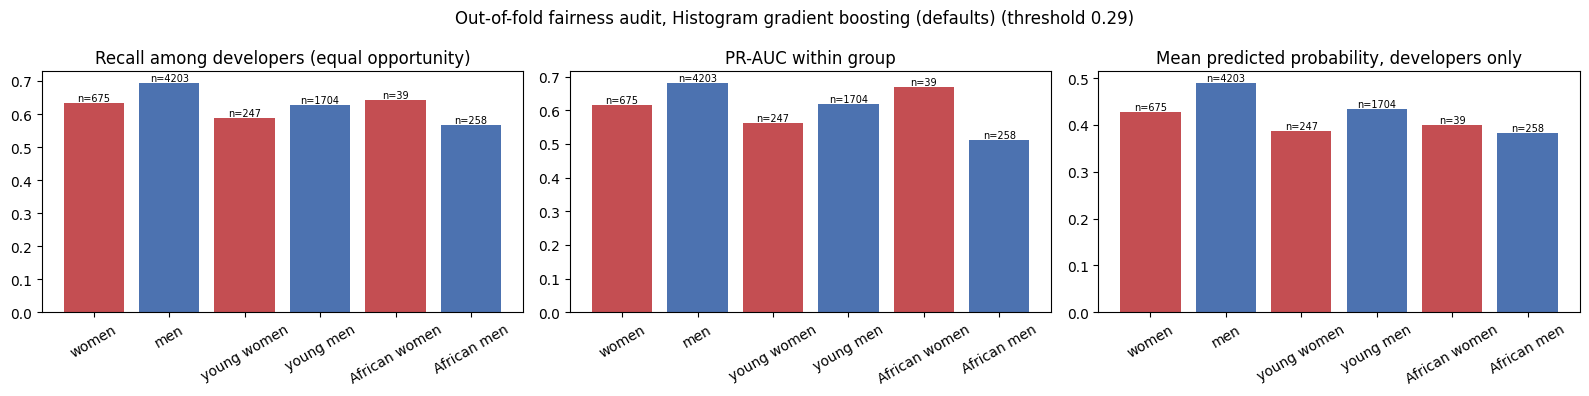

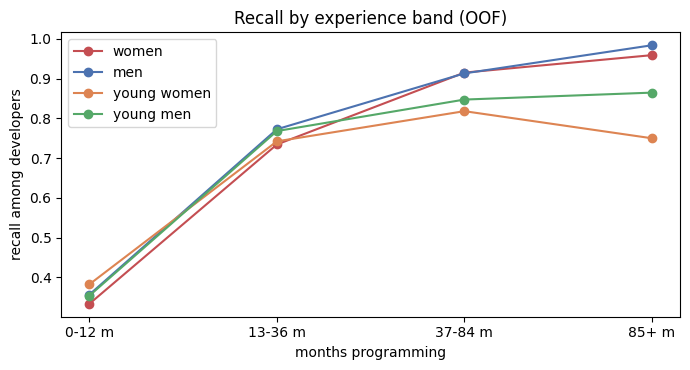

In [ ]:
order = ["women", "men", "young women", "young men", "African women", "African men"]
sub = FAIR.set_index("group").loc[order]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
cols_ = ["#C44E52", "#4C72B0"] * 3
ax[0].bar(order, sub["recall (equal opp.)"], color=cols_); ax[0].set_title("Recall among developers (equal opportunity)")
ax[1].bar(order, sub["pr_auc"], color=cols_); ax[1].set_title("PR-AUC within group")
ax[2].bar(order, sub["mean_score_of_developers"], color=cols_); ax[2].set_title("Mean predicted probability, developers only")
for a_ in ax: a_.tick_params(axis="x", rotation=30)
for a_, k in zip(ax, ("recall (equal opp.)", "pr_auc", "mean_score_of_developers")):
    for i, (v, n) in enumerate(zip(sub[k], sub["developers"])): a_.text(i, v, f"n={n}", ha="center", va="bottom", fontsize=7)
fig.suptitle(f"Out-of-fold fairness audit, {NAME[BEST_ML]} (threshold {thr:.2f})"); fig.tight_layout(); save(fig, "fairness_groups"); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.8))
for g, c in (("women", "#C44E52"), ("men", "#4C72B0"), ("young women", "#DD8452"), ("young men", "#55A868")):
    e = EXP[EXP.group == g]; ax.plot(e.experience.astype(str), e.recall, "o-", label=g, color=c)
ax.set(xlabel="months programming", ylabel="recall among developers", title="Recall by experience band (OOF)"); ax.legend()
fig.tight_layout(); save(fig, "fairness_experience"); plt.show()

### What this output tells us: the answer to the research question
**1. Women who are developers are recognised less reliably than men.**
* Among real developers, the model flags **63.4% of women vs 69.5% of men**.
* The gap is **−0.060**, 95% CI **[−0.100, −0.023]**. The interval excludes zero, so this is not noise.

**2. Young women (18–25): same direction, but not robust.**
* Recall is **58.7% vs 62.7%** for young men (gap **−0.040**, CI [−0.111, +0.020]). The interval includes zero.
* **The stability check (5 different random splits):**
  * Women vs men: mean gap **−0.065** (range −0.077 to −0.056); the CI excludes zero in **5 of 5** splits. **Robust.**
  * Young women vs young men: mean gap **−0.048** (range −0.060 to −0.030); the CI excludes zero in only **1 of 5** splits. **Not robust.**
* With only 247 young women developers, a gap of about 4–5 points cannot be reliably separated from noise.
* Real young women developers do receive lower average scores (0.388 vs 0.433; gap −0.045, CI [−0.081, −0.014]), which points the same way.
* **Honest answer:** the model under-recognises women. For young women the direction is the same, but the data are not enough to confirm a separate gap.

**3. It's a ranking problem, not just a threshold problem.**
* Within each group, PR-AUC is lower for women (0.614 vs 0.681; gap −0.067, CI [−0.109, −0.025]).
* Real women developers receive a lower **average score** (0.428 vs 0.490; gap −0.062, CI [−0.085, −0.040]).
* The model systematically gives women who have made it lower scores than men who have made it.

**4. Disparate impact (0.56) mostly reflects the different base rates.**
* Women are flagged about half as often, but they are also developers less often (10.8% vs 17.9%).
* With unequal base rates, equal flag rates, equal error rates and calibration cannot all hold at once (Kleinberg et al., 2017). So equal opportunity is the criterion that matters here.

**5. Experience does not explain it.**
* Women and men developers have the **same median experience (24 months)**.
* The gap is largest at **13–36 months**, where most developers fall: recall **0.734 for women vs 0.773 for men** (0.742 vs 0.768 for young women vs young men). It is small at 0–12 months (0.333 vs 0.357) and absent at 37–84 months (0.915 vs 0.913).
* So the gap sits in the early-career band, where the model is least certain and women's other features (degree, age, resources used) look more like learners'.

**6. Africa: too small to conclude.**
* There are 39 African women developers and 17 young African women developers.
* In this split their recall is actually *higher* than African men's (0.641 vs 0.566), but every interval includes zero.
* These numbers are **descriptive only**.

**7. Reducing the gap** (all respondents, out-of-fold, 95% CI)

| Variant | PR-AUC | Recall women / men | Gap women − men | Gap young women − young men |
|---|---|---|---|---|
| E6 baseline | 0.668 | 0.634 / 0.695 | −0.060 [−0.100, −0.020] | −0.040 [−0.109, +0.027] |
| E15 no gender input | 0.666 | 0.647 / 0.691 | −0.044 [−0.083, −0.004] | −0.026 [−0.094, +0.040] |
| E16 reweighting | 0.626 | 0.615 / 0.696 | −0.081 [−0.124, −0.042] | −0.071 [−0.137, −0.001] |
| E17 group threshold | 0.668 | 0.665 / 0.695 | −0.029 [−0.069, +0.012] | 0.000 [−0.066, +0.064] |

* **E15 (removing gender) helps a little but does not close the gap.** Other features act as proxies, which is why "fairness through unawareness" is not enough.
* **E16 (reweighting) backfires:** it costs accuracy (PR-AUC −0.042) and *widens* the gap.
* **E17 (a slightly lower threshold for women: 0.255 vs 0.289, chosen on validation) narrows the gap the most at no cost to PR-AUC or F1.** Its interval now includes zero. Group-specific thresholds raise legal and ethical questions, so a human-review step for borderline women candidates is a practical alternative.
* **The held-out test set alone** (102 women developers) shows the same direction with larger, noisier gaps (−0.157). This is why the out-of-fold analysis on all respondents is the main evidence.

## 13. Save the best models (for the Google Drive folder)
* Traditional: the full scikit-learn pipeline, preprocessing included (`.joblib`).
* Deep: Keras native `.keras`, legacy `.h5` and a TensorFlow SavedModel, plus the fitted preprocessor and country vocabulary the network needs (`keras_preprocessing.joblib`).

Each saved model is reloaded and checked to give identical predictions.

In [ ]:
joblib.dump(ART[BEST_ML]["model"], "models/best_traditional.joblib")
dl = ART[BEST_DL]["model"]
dl.save("models/best_deep.keras"); dl.save("models/best_deep.h5"); dl.export("models/best_deep_savedmodel")
joblib.dump({"preprocessor": PRE_DL, "country_vocab": COUNTRY_VOCAB, "feature_columns": cols_all,
             "threshold": THR[BEST_DL]}, "models/keras_preprocessing.joblib")
joblib.dump({"threshold": THR[BEST_ML], "feature_columns": ART[BEST_ML]["cols"]}, "models/traditional_threshold.joblib")
re_ml = joblib.load("models/best_traditional.joblib").predict_proba(SPLITS["test"][ART[BEST_ML]["cols"]])[:, 1]
seq = ART[BEST_DL]["builder"] is build_sequential
re_dl = tf.keras.models.load_model("models/best_deep.keras").predict(ARR["test"] if seq else {"tab": ARR["test"], "country": CTRY["test"]}, verbose=0).ravel()
print("Reloaded traditional identical:", np.allclose(re_ml, PREDS[BEST_ML]["test"]))
print("Reloaded deep identical:", np.allclose(re_dl, PREDS[BEST_DL]["test"], atol=1e-5))
for f in sorted(os.listdir("models")): print(" ", f)

Saved artifact at 'models/best_deep_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 119), dtype=tf.float32, name='tab'), TensorSpec(shape=(None,), dtype=tf.int32, name='country')]
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140581443567888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581443579984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581443583440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581443581328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581323869648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581443581904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581443571920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581323873104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581323873296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140581323866576: TensorSp

Reloaded traditional identical: True
Reloaded deep identical: True
  best_deep.h5
  best_deep.keras
  best_deep_savedmodel
  best_traditional.joblib
  keras_preprocessing.joblib
  traditional_threshold.joblib


In [ ]:
import shutil, importlib.metadata as md_
shutil.make_archive("experiment_logs", "zip", ".", "logs")
if os.path.isdir("wandb"): shutil.make_archive("wandb_offline_runs", "zip", ".", "wandb")
pk = ["numpy", "pandas", "scikit-learn", "tensorflow", "tensorflow-cpu", "matplotlib", "joblib", "wandb", "tensorboard", "pycountry-convert"]
with open("requirements_frozen.txt", "w") as f:
    for p in pk:
        try: f.write(f"{p}=={md_.version(p)}\n")
        except md_.PackageNotFoundError: pass
print(open("requirements_frozen.txt").read()); print("View logs with:  tensorboard --logdir logs")

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
tensorflow==2.21.0
tensorflow-cpu==2.21.0
matplotlib==3.10.0
joblib==1.6.0
wandb==0.28.1
tensorboard==2.21.0
pycountry-convert==0.7.2

View logs with:  tensorboard --logdir logs


## 14. Conclusions
1. **Answer to the research question: no for women overall; not proven for young women.** Models that recognise who has made it into a developer job do **not** recognise women as reliably as men.
   * The best traditional model finds **63.4% of women developers vs 69.5% of men** (gap −0.060, 95% CI [−0.100, −0.023]).
   * This holds across 5 different random splits (mean gap −0.065; significant in all 5).
   * For **young women** the gap points the same way, but it is **not robust**: −0.040 in the main split (interval includes zero), mean −0.048 over 5 splits, significant in only 1 of 5. Confirming a young-women-specific gap needs more young women developers in the data.
   * The model also gives real women developers lower scores on average, so the problem is in the ranking, not just the cut-off.
2. **The gap is not explained by experience.** Women and men developers have the same median experience. The gap is concentrated among developers with 1–3 years of experience, and among non-traditional, early-career profiles where women are over-represented.
3. **Traditional ML beats deep learning here.**
   * Default gradient boosting (E6, test PR-AUC 0.654, ROC-AUC 0.887) beats the best Keras network (E12, 0.629) by +0.025 (CI [+0.008, +0.042]).
   * It is also faster, better calibrated and easier to explain.
   * Unregularised networks overfit within a few epochs; regularisation (E12) fixed that, and the country embedding was the only architectural change that helped.
   * Hyper-parameter tuning (E7) reduced variance but did not improve validation PR-AUC: the search found a plateau.
4. **Learning intensity, especially months of programming, drives prediction.** Community and mentorship features add almost nothing to *prediction*, but they are used mainly by women (11.3% vs 1.4%). Programmes should value them even though models ignore them.
5. **Fixing the gap.** Removing gender narrows it slightly; reweighting makes it worse. A validated group-specific threshold narrows it to −0.029 (CI includes zero) at no accuracy cost. Any job-readiness tool used by a mentorship or placement programme for young women should be **audited for equal opportunity before use**.
6. **Limitations.**
   * Self-selected 2018 online survey.
   * Cross-sectional: recognises profiles, does not forecast.
   * Binary gender field.
   * Possible reverse causality for some features.
   * Only 323 African women (39 developers), so Africa results are descriptive.